# SHAP & Adversarial Attacks — Lopez17CNN, BiflowTransformer, NetMamba

Questo notebook si occupa del calcolo dei valori SHAP sui tre modelli in analisi, passando poi a svolgere la parte degli Adversarial Attacks sui possibili esperimenti presi in analisi. Il Notebook è diviso concettualmente da due fasi, quella dedita al calcolo degli SHAP per passare alla parte Adversarial



# Fase 1 SHAP — Lopez17CNN, BiflowTransformer, NetMamba

## Obiettivo
Calcolare i valori SHAP sui tre modelli usando **esattamente lo stesso insieme di campioni**,
così che i confronti tra modello e modello siano basati su dati identici.

## Strategia
1. Si caricano i tre modelli con i rispettivi loader/dataset (ognuno con i propri pesi e args).
2. Per ciascun modello si individuano gli indici del test set **classificati correttamente**,
   per ciascuna delle 6 classi (diagonale della matrice di confusione).
3. Si verifica che i tre test set siano **allineati indice-per-indice** (stesso ordine di
   campioni). Questo è garantito se i tre run sono stati addestrati con lo stesso dataset,
   stesso `num_pkts`, stessi `fields` e stesso `seed` passati a `get_loaders` — condizione
   tipica quando si confrontano architetture diverse sullo stesso esperimento.
4. Si calcola l'**intersezione** degli indici corretti per classe tra i tre modelli: questo è
   l'insieme di campioni che *tutti e tre* i modelli classificano correttamente.
5. Da questa intersezione si estrae un campione fisso per classe (`NUM_SAMPLES_TO_EXPLAIN`),
   gli **stessi indici** vengono usati per calcolare SHAP su tutti e tre i modelli.
6. Gli indici usati vengono salvati su disco (in `shap_common/`) così da poter essere riusati
   o ispezionati in seguito.
7. Per ciascun modello si calcolano i valori SHAP (`GradientExplainer`), si salvano i `.pickle`
   e si generano i grafici/PDF per ciascuna classe.

## ⚠️ Importante
Se i tre run **non condividono lo stesso seed/split**, l'indice `i` del test set di un modello
non corrisponde necessariamente allo stesso flusso di rete dell'indice `i` di un altro modello.
La cella di **sanity-check allineamento** (sezione 6) verifica questa condizione confrontando
le etichette vere e (quando possibile) i valori normalizzati dei campioni stessi: se il
controllo fallisce, il notebook si ferma con un errore esplicativo invece di produrre
risultati silenziosamente sbagliati.

In [2]:

import sys
import os
import json
import math
import pickle
import random
import shutil
from glob import glob
from argparse import Namespace
from collections import OrderedDict

import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F

import shap
from tqdm import tqdm
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sn

from sklearn.metrics import classification_report, f1_score

# Repo del progetto (stessa convenzione dei notebook originali: eseguire da una
# sottocartella, es. notebooks/, in modo che '../' punti alla root del repo)
sys.path.append('../')

from datasets.data_loader import get_loaders
from util.xai_utils import *   # plot_cm e altre utility condivise dal framework
import utils

#device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device = 'cpu'
print(f'[INFO] Device: {device}')


/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[INFO] Device: cpu


### Dipendenze opzionali per NetMamba
`NetMamba` usa `einops` e, se disponibili, i kernel CUDA di `mamba_ssm` / `causal_conv1d`.
Se questi ultimi non sono installati il modello ricade automaticamente su un'implementazione
pura PyTorch (`_selective_scan_ref`), interamente differenziabile e quindi compatibile con
`shap.GradientExplainer` anche su CPU. Se necessario, decommenta la cella sottostante per
installare le dipendenze mancanti.

In [3]:

# Decommenta se l'ambiente non ha già le dipendenze installate
# !pip install -q einops
# !pip install -q causal-conv1d --no-build-isolation
# !pip install -q mamba-ssm --no-build-isolation

from einops import rearrange, repeat

try:
    from causal_conv1d import causal_conv1d_fn, causal_conv1d_update
except ImportError:
    causal_conv1d_fn = causal_conv1d_update = None
try:
    from mamba_ssm.ops.selective_scan_interface import selective_scan_fn, mamba_inner_fn
except ImportError:
    selective_scan_fn = mamba_inner_fn = None
try:
    from mamba_ssm.ops.triton.selective_state_update import selective_state_update
except ImportError:
    selective_state_update = None
try:
    from mamba_ssm.ops.triton.layernorm import RMSNorm, layer_norm_fn, rms_norm_fn
except ImportError:
    RMSNorm = layer_norm_fn = rms_norm_fn = None

print('[INFO] mamba kernels disponibili:', mamba_inner_fn is not None)


[INFO] mamba kernels disponibili: False


## 2. Configurazione

Imposta qui i percorsi dei checkpoint/args dei tre modelli e i parametri condivisi
per la selezione dei campioni e per SHAP.

In [4]:

# ----------------------------------------------------------------------------
# Percorsi modello (adatta ai tuoi run)
# ----------------------------------------------------------------------------
MODEL_PATHS = {
    'lopez': {
        'base_model_path': '../../results/ton-iot_6classes_scratch_test_1/models/task0-1781616022677042.ckpt',
        'args_path':       '../../results/ton-iot_6classes_scratch_test_1/args-1781616022677042.txt',
    },
    'transformer': {
        'base_model_path': '../../results/ton-iot_6classes_scratch_test_transformer/models/task0-1781641169236742.ckpt',
        'args_path':       '../../results/ton-iot_6classes_scratch_test_transformer/args-1781641169236742.txt',
    },
    'netmamba': {
        'base_model_path': '../../results/ton-iot_6classes_scratch_NetMamba/models/task0-1782396588593868.ckpt',
        'args_path':        '../../results/ton-iot_6classes_scratch_NetMamba/args-1782396588593868.txt'
},
}

# Nome leggibile usato in plot/cartelle/legenda
MODEL_DISPLAY_NAME = {
    'lopez':       'Lopez17CNN',
    'transformer': 'BiflowTransformer',
    'netmamba':    'NetMamba',
}

# Class order per ciascun modello: aggiorna leggendo la riga 'Class order' dello
# stdout del relativo run (di default sono allineati, come nei notebook originali).
CLASS_ORDER = {
    'lopez':       [1, 2, 4, 3, 5, 0],
    'transformer': [1, 2, 4, 3, 5, 0],
    'netmamba':    [1, 2, 4, 3, 5, 0],
}

CLASS_NAMES = ['benign', 'dos', 'infog-scan-port', 'inject', 'malwr', 'mitm-arpspoof']
NUM_CLASSES = len(CLASS_NAMES)

# ----------------------------------------------------------------------------
# Parametri SHAP
# ----------------------------------------------------------------------------
NUM_BACKGROUND_PER_CLASS  = 100   # campioni di training per classe usati come background
NUM_SAMPLES_TO_EXPLAIN    = 200   # campioni (comuni ai 3 modelli) spiegati per classe

# ----------------------------------------------------------------------------
# Cartelle di output
# ----------------------------------------------------------------------------
OUTDIR_COMMON = './shap_common/'
OUTDIR_MODEL = {
    'lopez':       './shap_lopez/',
    'transformer': './shap_transformer/',
    'netmamba':    './shap_netmamba/',
}
for d in [OUTDIR_COMMON] + list(OUTDIR_MODEL.values()):
    os.makedirs(d, exist_ok=True)

SEED = 42
utils.seed_everything(seed=SEED)
random.seed(SEED)
np.random.seed(SEED)
print('[INFO] Configurazione caricata.')


[INFO] Configurazione caricata.


## 3. Componenti di architettura condivise

In [40]:

class PositionalEncoding(nn.Module):
    '''Positional encoding sinusoidale condiviso da BiflowTransformer e NetMamba.'''
    def __init__(self, d_model, max_len=512, dropout=0.0):
        super().__init__()
        self.d_model = d_model
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.register_buffer("pe", self._build_pe(max_len, d_model), persistent=False)

    @staticmethod
    def _build_pe(max_len, d_model):
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)

    def _extend(self, new_len: int):
        if new_len > self.pe.size(1):
            self.pe = self._build_pe(new_len, self.d_model).to(self.pe.device, self.pe.dtype)

    def forward(self, x):
        L = x.size(1)
        if L > self.pe.size(1):
            self._extend(L)
        pe = self.pe[:, :L].to(dtype=x.dtype, device=x.device)
        x = x * math.sqrt(self.d_model) + pe
        return self.dropout(x)


class SoftmaxWrapper(nn.Module):
    '''Avvolge un modello che restituisce logit grezzi in modo che SHAP riceva probabilità.'''
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return F.softmax(self.model(x), dim=1)


### 3.1 Lopez17CNN (`scratch` CNN)

In [41]:

class Lopez17CNN(nn.Module):
    def __init__(self):
        super(Lopez17CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=(4, 2), stride=(1, 1), padding=0)
        self.relu1 = nn.ReLU()
        self.max1 = nn.MaxPool2d((3, 2), (1, 1), 0)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=(4, 2), stride=(1, 1), padding=0)
        self.max2 = nn.MaxPool2d((3, 1), stride=(1, 1), padding=0)
        self.relu2 = nn.ReLU()
        self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(10 * 6 * 64, 200)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(200, 6)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = F.pad(x, (0, 1) + (1, 2))
        x = self.conv1(x)
        x = self.relu1(x)
        x = F.pad(x, (0, 1) + (1, 1))
        x = self.max1(x)
        x = self.bn1(x)
        x = F.pad(x, (0, 1) + (1, 2))
        x = self.conv2(x)
        x = self.relu2(x)
        x = F.pad(x, (0, 0) + (1, 1))
        x = self.max2(x)
        x = self.bn2(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.fc2(x)
        x = self.softmax(x)
        return x


def build_lopez_model(base_model_path):
    '''Costruisce e carica i pesi del Lopez17CNN. Restituisce un modello che produce probabilità.'''
    model = Lopez17CNN().to(device)

    base_model = torch.load(base_model_path, map_location=device)
    if 'heads.0.weight' in base_model:
        base_model['model.fc2.weight'] = base_model.pop('heads.0.weight')
    if 'heads.0.bias' in base_model:
        base_model['model.fc2.bias'] = base_model.pop('heads.0.bias')

    state_dict = OrderedDict()
    for k, v in base_model.items():
        new_key = '.'.join(k.split('.')[1:]) if k.startswith('model.') else k
        state_dict[new_key] = v

    model.load_state_dict(state_dict)
    model.eval()
    return model


### 3.2 BiflowTransformer

In [42]:

class BiflowTransformer(nn.Module):
    def __init__(self, num_pkts, num_fields, num_classes=10, dropout=0.1, **kwargs):
        super().__init__()

        d_model = kwargs.get('d_model', 128)
        nhead = kwargs.get('nhead', 4)
        dim_feedforward = kwargs.get('dim_feedforward', 512)
        out_features_size = kwargs.get('out_features_size', 200)

        self.in_proj = nn.Linear(num_fields, d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))
        self.positional_encoding = PositionalEncoding(d_model, max_len=num_pkts + 1, dropout=dropout)

        self.transformer_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dropout=dropout,
            dim_feedforward=dim_feedforward,
            activation='gelu',
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(self.transformer_layer, num_layers=4)

        self.fc1 = nn.Linear(d_model, out_features_size)
        self.fc = nn.Linear(out_features_size, num_classes)
        self.head_var = 'fc'

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def extract_features(self, x):
        cls_tokens = self.cls_token.expand(x.shape[0], -1, -1)
        x = x.squeeze(1)
        B, _, _ = x.shape

        flag = x[..., 0]
        pad_mask = (flag == 0)
        pad_mask = torch.cat(
            [torch.zeros(B, 1, dtype=torch.bool, device=x.device), pad_mask], dim=1
        )

        x = self.in_proj(x)
        x = torch.cat((cls_tokens, x), dim=1)
        x = self.positional_encoding(x)
        x = self.transformer_encoder(x, src_key_padding_mask=pad_mask)
        cls_output = x[:, 0]
        x = self.fc1(cls_output)
        return x

    def forward(self, x):
        out = F.gelu(self.extract_features(x))
        out = self.fc(out)
        # Softmax interno, già presente nel modello originale: restituisce probabilità
        return F.softmax(out, dim=1)


def build_transformer_model(base_model_path, num_pkts, num_fields, num_classes=6):
    model = BiflowTransformer(num_pkts=num_pkts, num_fields=num_fields, num_classes=num_classes).to(device)

    base_model = torch.load(base_model_path, map_location=device)
    if 'heads.0.weight' in base_model:
        base_model['model.fc.weight'] = base_model.pop('heads.0.weight')
    if 'heads.0.bias' in base_model:
        base_model['model.fc.bias'] = base_model.pop('heads.0.bias')

    state_dict = OrderedDict()
    for k, v in base_model.items():
        new_key = '.'.join(k.split('.')[1:]) if k.startswith('model.') else k
        state_dict[new_key] = v

    model.load_state_dict(state_dict)
    model.eval()
    return model


### 3.3 NetMamba

In [43]:

class Mamba(nn.Module):
    def __init__(
        self, d_model, d_state=16, d_conv=4, expand=2, dt_rank="auto",
        dt_min=0.001, dt_max=0.1, dt_init="random", dt_scale=1.0, dt_init_floor=1e-4,
        conv_bias=True, bias=False, use_fast_path=True, layer_idx=None, device=None, dtype=None,
    ):
        factory_kwargs = {"device": device, "dtype": dtype}
        super().__init__()
        self.d_model = d_model
        self.d_state = d_state
        self.d_conv = d_conv
        self.expand = expand
        self.d_inner = int(self.expand * self.d_model)
        self.dt_rank = math.ceil(self.d_model / 16) if dt_rank == "auto" else dt_rank
        self.use_fast_path = use_fast_path
        self.layer_idx = layer_idx

        self.in_proj = nn.Linear(self.d_model, self.d_inner * 2, bias=bias, **factory_kwargs)
        self.conv1d = nn.Conv1d(
            in_channels=self.d_inner, out_channels=self.d_inner, bias=conv_bias,
            kernel_size=d_conv, groups=self.d_inner, padding=d_conv - 1, **factory_kwargs,
        )
        self.activation = "silu"
        self.act = nn.SiLU()
        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + self.d_state * 2, bias=False, **factory_kwargs)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True, **factory_kwargs)

        dt_init_std = self.dt_rank ** -0.5 * dt_scale
        if dt_init == "constant":
            nn.init.constant_(self.dt_proj.weight, dt_init_std)
        elif dt_init == "random":
            nn.init.uniform_(self.dt_proj.weight, -dt_init_std, dt_init_std)
        else:
            raise NotImplementedError

        dt = torch.exp(
            torch.rand(self.d_inner, **factory_kwargs) * (math.log(dt_max) - math.log(dt_min))
            + math.log(dt_min)
        ).clamp(min=dt_init_floor)
        inv_dt = dt + torch.log(-torch.expm1(-dt))
        with torch.no_grad():
            self.dt_proj.bias.copy_(inv_dt)
        self.dt_proj.bias._no_reinit = True

        A = repeat(
            torch.arange(1, self.d_state + 1, dtype=torch.float32, device=device),
            "n -> d n", d=self.d_inner,
        ).contiguous()
        self.A_log = nn.Parameter(torch.log(A))
        self.A_log._no_weight_decay = True
        self.D = nn.Parameter(torch.ones(self.d_inner, device=device))
        self.D._no_weight_decay = True
        self.out_proj = nn.Linear(self.d_inner, self.d_model, bias=bias, **factory_kwargs)

    def forward(self, hidden_states, inference_params=None):
        '''hidden_states: (B, L, D)  ->  (B, L, D)'''
        batch, seqlen, dim = hidden_states.shape

        xz = rearrange(
            self.in_proj.weight @ rearrange(hidden_states, "b l d -> d (b l)"),
            "d (b l) -> b d l", l=seqlen,
        )
        if self.in_proj.bias is not None:
            xz = xz + rearrange(self.in_proj.bias.to(dtype=xz.dtype), "d -> d 1")

        A = -torch.exp(self.A_log.float())

        if self.use_fast_path and mamba_inner_fn is not None and inference_params is None:
            out = mamba_inner_fn(
                xz, self.conv1d.weight, self.conv1d.bias, self.x_proj.weight,
                self.dt_proj.weight, self.out_proj.weight, self.out_proj.bias,
                A, None, None, self.D.float(),
                delta_bias=self.dt_proj.bias.float(), delta_softplus=True,
            )
        else:
            # Fallback puro-PyTorch, differenziabile (necessario per GradientExplainer su CPU)
            x, z = xz.chunk(2, dim=1)
            if causal_conv1d_fn is None:
                x = self.act(self.conv1d(x)[..., :seqlen])
            else:
                x = causal_conv1d_fn(
                    x=x, weight=rearrange(self.conv1d.weight, "d 1 w -> d w"),
                    bias=self.conv1d.bias, activation=self.activation,
                )

            x_dbl = self.x_proj(rearrange(x, "b d l -> (b l) d"))
            dt, B, C = torch.split(x_dbl, [self.dt_rank, self.d_state, self.d_state], dim=-1)
            dt = self.dt_proj.weight @ dt.t()
            dt = rearrange(dt, "d (b l) -> b d l", l=seqlen)
            B = rearrange(B, "(b l) dstate -> b dstate l", l=seqlen).contiguous()
            C = rearrange(C, "(b l) dstate -> b dstate l", l=seqlen).contiguous()

            if selective_scan_fn is not None:
                y = selective_scan_fn(
                    x, dt, A, B, C, self.D.float(), z=z,
                    delta_bias=self.dt_proj.bias.float(), delta_softplus=True,
                    return_last_state=False,
                )
            else:
                dt_soft = F.softplus(dt + self.dt_proj.bias.float().unsqueeze(-1))
                y = self._selective_scan_ref(x, dt_soft, A, B, C, self.D, z)

            y = rearrange(y, "b d l -> b l d")
            out = self.out_proj(y)
        return out

    @staticmethod
    def _selective_scan_ref(u, delta, A, B, C, D, z):
        '''Implementazione di riferimento in PyTorch puro (lenta ma corretta e differenziabile).'''
        B_sz, d_inner, L = u.shape
        d_state = A.shape[1]
        deltaA = torch.exp(torch.einsum("bdl,dn->bdln", delta, A))
        deltaB_u = torch.einsum("bdl,bnl,bdl->bdln", delta, B, u)
        x = torch.zeros(B_sz, d_inner, d_state, device=u.device, dtype=u.dtype)
        ys = []
        for i in range(L):
            x = deltaA[:, :, i, :] * x + deltaB_u[:, :, i, :]
            y = torch.einsum("bdn,bn->bd", x, C[:, :, i])
            ys.append(y)
        y = torch.stack(ys, dim=2)
        y = y + u * D.unsqueeze(-1)
        y = y * F.silu(z)
        return y


class MambaBlock(nn.Module):
    def __init__(self, dim, layer_idx=None):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.mixer = Mamba(d_model=dim, layer_idx=layer_idx)

    def forward(self, x, residual=None):
        residual = (x + residual) if residual is not None else x
        hidden = self.norm(residual)
        out = self.mixer(hidden)
        return out, residual


class NetMamba(nn.Module):
    def __init__(
        self, pretrained: bool = False, num_pkts: int = 10, num_fields: int = 6,
        out_features_size=None, scale: float = 1.0,
        d_model: int = 128, depth: int = 4, d_state: int = 16,
    ):
        super().__init__()
        d_model = max(32, int(d_model * scale))
        self.num_pkts = num_pkts
        self.num_fields = num_fields
        self.d_model = d_model
        self.out_features_size = out_features_size if out_features_size is not None else d_model

        self.input_proj = nn.Linear(num_fields, d_model)
        self.pos_embed = PositionalEncoding(d_model=d_model, max_len=num_pkts)
        self.blocks = nn.ModuleList([MambaBlock(dim=d_model, layer_idx=i) for i in range(depth)])
        self.norm_f = nn.LayerNorm(d_model)
        self.fc1 = nn.Linear(d_model, self.out_features_size)
        self.fc = nn.Linear(self.out_features_size, 10)  # placeholder, sovrascritto a num_classes reali
        self.head_var = 'fc'
        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(self.input_proj.weight, std=0.02)
        nn.init.zeros_(self.input_proj.bias)
        nn.init.trunc_normal_(self.fc1.weight, std=0.02)
        nn.init.zeros_(self.fc1.bias)

    def forward(self, x):
        out = F.gelu(self.extract_features(x))
        out = self.fc(out)
        return out  # logit grezzi: il softmax viene applicato dal SoftmaxWrapper

    def extract_features(self, x):
        if x.dim() == 4:
            x = x.squeeze(1)
        if x.dim() == 3:
            if x.shape[1] == self.num_fields and x.shape[2] == self.num_pkts:
                x = x.permute(0, 2, 1)
        elif x.dim() == 2:
            x = x.view(x.size(0), self.num_pkts, self.num_fields)

        x = x.float()
        x = self.input_proj(x)
        x = self.pos_embed(x)

        residual = None
        for block in self.blocks:
            x, residual = block(x, residual)

        x = self.norm_f(x + residual if residual is not None else x)
        x = x.mean(dim=1)
        x = self.fc1(x)
        return x


def build_netmamba_model(base_model_path, num_pkts, num_fields, num_classes=6):
    core_model = NetMamba(num_pkts=num_pkts, num_fields=num_fields).to(device)
    core_model.fc = nn.Linear(core_model.out_features_size, num_classes).to(device)

    base_model = torch.load(base_model_path, map_location=device)
    if 'heads.0.weight' in base_model:
        base_model['model.fc.weight'] = base_model.pop('heads.0.weight')
    if 'heads.0.bias' in base_model:
        base_model['model.fc.bias'] = base_model.pop('heads.0.bias')

    state_dict = OrderedDict()
    for k, v in base_model.items():
        new_key = '.'.join(k.split('.')[1:]) if k.startswith('model.') else k
        state_dict[new_key] = v

    missing, unexpected = core_model.load_state_dict(state_dict, strict=False)
    print('[load_state_dict][netmamba] missing:', missing)
    print('[load_state_dict][netmamba] unexpected:', unexpected)
    core_model.eval()

    model = SoftmaxWrapper(core_model).to(device)
    model.eval()
    return model


## 4. Caricamento dati e costruzione dei tre modelli

Per ciascun modello: si caricano gli `args` del run, si seedano i loader e si costruiscono
`trn_loader`/`tst_loader`.

Tutto viene raccolto in un dizionario `MODELS[tag]` con le chiavi:
`args, scratch_model, trn_loader, tst_loader, trn_instances, tst_instances,
trn_targets_scratch, tst_targets_scratch, tst_targets_true, pred_true, argsort, field_names`.


In [44]:

def load_args(args_path):
    with open(args_path) as f:
        args = json.loads(f.read(), object_hook=lambda d: Namespace(**d))
    return args


def load_loaders(args):
    utils.seed_everything(seed=args.seed)
    trn_loader, val_loader, tst_loader, taskcla = get_loaders(
        args.datasets, args.num_tasks, args.nc_first_task, args.nc_incr_tasks, args.batch_size,
        validation=0.1, num_workers=0, num_pkts=args.num_pkts, fields=args.fields,
        seed=args.seed, pin_memory=False
    )
    return trn_loader, val_loader, tst_loader, taskcla


def predict_with_model(scratch_model, instances, class_order, batch_size=512):
    '''Esegue il forward (a batch, per non saturare la memoria) e mappa il neurone
    predetto sulla classe canonica tramite class_order.'''
    scratch_model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(instances), batch_size):
            batch = instances[i:i + batch_size].float().to(device)
            probs = scratch_model(batch).cpu().numpy()
            preds.extend(np.argmax(probs, axis=1).tolist())
    pred_true = [class_order[p] for p in preds]
    return pred_true


MODELS = {}

for tag in ['lopez', 'transformer', 'netmamba']:
    print('=' * 70)
    print(f'[INFO] Caricamento modello: {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)

    paths = MODEL_PATHS[tag]
    args = load_args(paths['args_path'])
    print(f'  seed={args.seed} | num_pkts={args.num_pkts} | fields={args.fields}')

    trn_loader, val_loader, tst_loader, taskcla = load_loaders(args)

    trn_instances = torch.from_numpy(np.concatenate([x for x, y in trn_loader[0]], axis=0))
    tst_instances = torch.from_numpy(np.concatenate([x for x, y in tst_loader[0]], axis=0))
    trn_targets_scratch = np.concatenate([y for x, y in trn_loader[0]], axis=0)
    tst_targets_scratch = np.concatenate([y for x, y in tst_loader[0]], axis=0)

    class_order = CLASS_ORDER[tag]
    tst_targets_true = np.array([class_order[e] for e in tst_targets_scratch])
    trn_targets_true = np.array([class_order[e] for e in trn_targets_scratch])
    argsort = np.argsort(class_order)

    if tag == 'lopez':
        scratch_model = build_lopez_model(paths['base_model_path'])
    elif tag == 'transformer':
        scratch_model = build_transformer_model(
            paths['base_model_path'], num_pkts=args.num_pkts, num_fields=len(args.fields),
            num_classes=NUM_CLASSES)
    elif tag == 'netmamba':
        scratch_model = build_netmamba_model(
            paths['base_model_path'], num_pkts=args.num_pkts, num_fields=len(args.fields),
            num_classes=NUM_CLASSES)

    pred_true = predict_with_model(scratch_model, tst_instances, class_order)

    MODELS[tag] = dict(
        args=args,
        scratch_model=scratch_model,
        trn_loader=trn_loader, tst_loader=tst_loader,
        trn_instances=trn_instances, tst_instances=tst_instances,
        trn_targets_scratch=trn_targets_scratch, tst_targets_scratch=tst_targets_scratch,
        trn_targets_true=trn_targets_true, tst_targets_true=tst_targets_true,
        pred_true=np.array(pred_true),
        class_order=class_order, argsort=argsort,
        field_names=list(args.fields),
    )
    print(f'  [OK] Test set: {len(tst_instances)} campioni | Train set: {len(trn_instances)} campioni')

print('\n[INFO] Tutti e tre i modelli sono stati caricati in MODELS.')


[INFO] Caricamento modello: Lopez17CNN
  seed=100 | num_pkts=10 | fields=['PL', 'IAT', 'DIR', 'WIN', 'TTL', 'FLG']
PREP_DF ton-iot_100pkts_firstDIRfixed_PLfixed_6f_1p-mt1m_10p-mt100k_clean_uniform-label_6classes.parquet /nas/data/datasets/ton-iot/ton-iot_100pkts_firstDIRfixed_PLfixed_6f_1p-mt1m_10p-mt100k_clean_uniform-label_6classes_prep100.parquet True
Class order:  [1, 2, 4, 3, 5, 0]
  [OK] Test set: 72220 campioni | Train set: 151653 campioni
[INFO] Caricamento modello: BiflowTransformer
  seed=100 | num_pkts=10 | fields=['PL', 'IAT', 'DIR', 'WIN', 'TTL', 'FLG']
PREP_DF ton-iot_100pkts_firstDIRfixed_PLfixed_6f_1p-mt1m_10p-mt100k_clean_uniform-label_6classes.parquet /nas/data/datasets/ton-iot/ton-iot_100pkts_firstDIRfixed_PLfixed_6f_1p-mt1m_10p-mt100k_clean_uniform-label_6classes_prep100.parquet True
Class order:  [1, 2, 4, 3, 5, 0]
  [OK] Test set: 72220 campioni | Train set: 151653 campioni
[INFO] Caricamento modello: NetMamba
  seed=100 | num_pkts=10 | fields=['PL', 'IAT', 'DIR',

## 5. Matrici di confusione per i tre modelli

--- Lopez17CNN ---
saved at ./results/Confusion_Matrices/Lopez17CNN/CM_6_classi_test.pdf


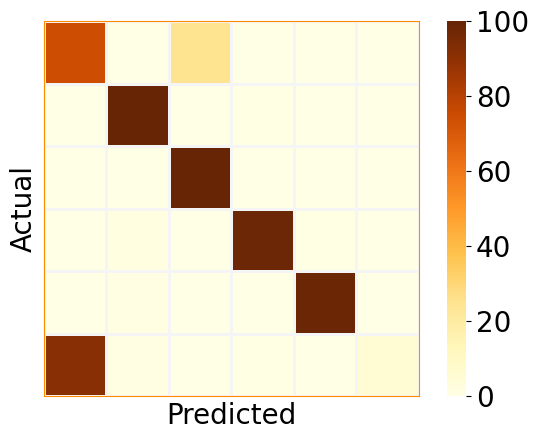

--- BiflowTransformer ---
saved at ./results/Confusion_Matrices/BiflowTransformer/CM_6_classi_test.pdf


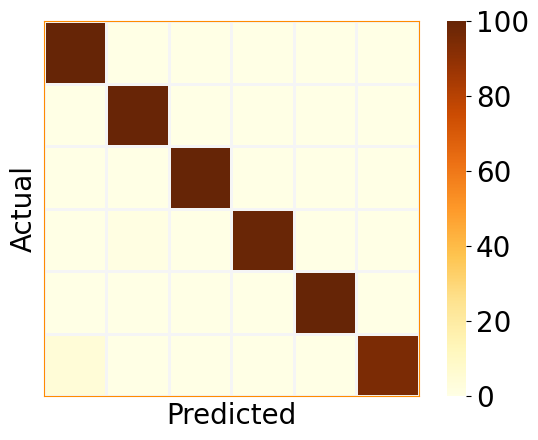

--- NetMamba ---
saved at ./results/Confusion_Matrices/NetMamba/CM_6_classi_test.pdf


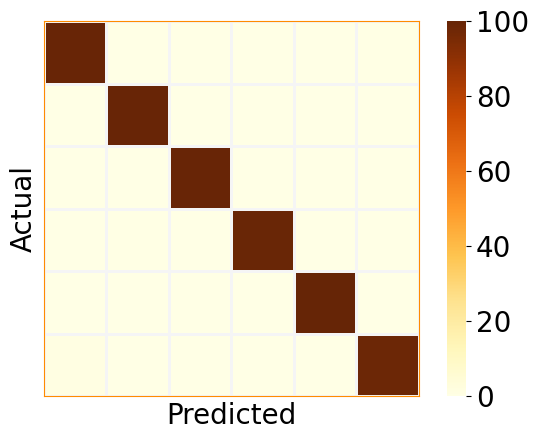

In [45]:

for tag in ['lopez', 'transformer', 'netmamba']:
    m = MODELS[tag]
    print(f'--- {MODEL_DISPLAY_NAME[tag]} ---')
    plot_cm(
        targets=m['tst_targets_true'],
        pred=m['pred_true'],
        appr=MODEL_DISPLAY_NAME[tag],
        title='CM_6_classi_test',
        binary=False
    )


## 6. Indici corretti per classe (per modello) + verifica allineamento

Per ciascun modello si individuano, per ciascuna classe, gli indici del test set in cui
etichetta vera e predizione coincidono (diagonale della matrice di confusione).

Subito dopo viene eseguita una **verifica di allineamento** tra i tre test set: se i tre
loader sono stati costruiti con lo stesso dataset/seed/split, l'indice `i` deve riferirsi
allo stesso identico campione in tutti e tre i modelli. Verifichiamo questo confrontando
(1) le etichette vere campione-per-campione e (2) — quando i `field_names` coincidono — i
valori normalizzati dei campioni stessi.

In [46]:

correct_idx_per_model = {}

for tag in ['lopez', 'transformer', 'netmamba']:
    m = MODELS[tag]
    correct_dict = {}
    print(f'=== {MODEL_DISPLAY_NAME[tag]}: istanze classificate correttamente (diagonale) ===')
    for c in range(NUM_CLASSES):
        corretti_c = np.where((m['tst_targets_true'] == c) & (m['pred_true'] == c))[0]
        correct_dict[c] = corretti_c
        totali_c = np.where(m['tst_targets_true'] == c)[0]
        if len(totali_c) > 0:
            perc = len(corretti_c) * 100 / len(totali_c)
            print(f'  Classe {CLASS_NAMES[c].upper():20s}: {perc:6.2f}% ({len(corretti_c)}/{len(totali_c)})')
        else:
            print(f'  Classe {CLASS_NAMES[c].upper():20s}: nessuna istanza nel test set')

    correct_idx_per_model[tag] = correct_dict

    # Salviamo anche il dizionario per-modello (compatibilità con i notebook originali)
    with open(os.path.join(OUTDIR_MODEL[tag], 'correct_instances_diagonal.pickle'), 'wb') as fp:
        pickle.dump(correct_dict, fp, protocol=pickle.HIGHEST_PROTOCOL)
    print()


=== Lopez17CNN: istanze classificate correttamente (diagonale) ===
  Classe BENIGN              :  74.38% (19633/26394)
  Classe DOS                 :  99.24% (15951/16073)
  Classe INFOG-SCAN-PORT     :  99.42% (4655/4682)
  Classe INJECT              :  98.05% (11724/11957)
  Classe MALWR               :  98.69% (11366/11517)
  Classe MITM-ARPSPOOF       :   6.14% (98/1597)

=== BiflowTransformer: istanze classificate correttamente (diagonale) ===
  Classe BENIGN              :  99.71% (26317/26394)
  Classe DOS                 :  99.38% (15974/16073)
  Classe INFOG-SCAN-PORT     :  99.62% (4664/4682)
  Classe INJECT              :  98.86% (11821/11957)
  Classe MALWR               :  99.87% (11502/11517)
  Classe MITM-ARPSPOOF       :  94.74% (1513/1597)

=== NetMamba: istanze classificate correttamente (diagonale) ===
  Classe BENIGN              :  99.51% (26265/26394)
  Classe DOS                 :  99.23% (15949/16073)
  Classe INFOG-SCAN-PORT     :  99.47% (4657/4682)
  Classe 

In [47]:

# ----------------------------------------------------------------------------
# Sanity-check: i tre test set sono allineati indice-per-indice?
# ----------------------------------------------------------------------------
print('=== Verifica allineamento dei test set ===')

tags = ['lopez', 'transformer', 'netmamba']
lengths = {t: len(MODELS[t]['tst_targets_true']) for t in tags}
print('Numero di campioni nel test set per modello:', lengths)

same_length = len(set(lengths.values())) == 1
if not same_length:
    raise RuntimeError(
        '[ERRORE] I test set dei tre modelli hanno lunghezze diverse: '
        f'{lengths}. Indici non comparabili tra modelli: verifica che i tre run '
        'condividano stesso dataset/seed/num_pkts.'
    )

# 1) Confronto delle etichette vere campione-per-campione
labels_ref = MODELS['lopez']['tst_targets_true']
labels_match = {}
for t in tags[1:]:
    labels_match[t] = bool(np.array_equal(labels_ref, MODELS[t]['tst_targets_true']))
print('Etichette vere identiche rispetto a lopez:', labels_match)

# 2) Confronto dei valori normalizzati dei campioni, riallineando i field_names se necessario
def reorder_fields(instances, src_fields, dst_fields):
    '''Riordina l'ultimo asse (campi) di un tensore (N, 1, num_pkts, num_fields)
    secondo l'ordine target dst_fields, usando src_fields come ordine sorgente.'''
    idx = [src_fields.index(f) for f in dst_fields]
    return instances[..., idx]

values_match = {}
ref_fields = MODELS['lopez']['field_names']
ref_instances = MODELS['lopez']['tst_instances'].numpy()

for t in tags[1:]:
    other_fields = MODELS[t]['field_names']
    other_instances = MODELS[t]['tst_instances'].numpy()
    if sorted(other_fields) != sorted(ref_fields):
        print(f'  [WARN] field set diverso per {t} ({other_fields} vs {ref_fields}): '
              'salto il confronto dei valori, mi affido solo alle etichette.')
        values_match[t] = None
        continue
    other_reordered = reorder_fields(other_instances, other_fields, ref_fields)
    values_match[t] = bool(np.allclose(ref_instances, other_reordered, atol=1e-5))

print('Valori dei campioni identici rispetto a lopez (dopo riallineamento campi):', values_match)

aligned = same_length and all(labels_match.values()) and all(
    v in (True, None) for v in values_match.values()
)

if not aligned:
    raise RuntimeError(
        '[ERRORE] I test set dei tre modelli NON risultano allineati indice-per-indice.\n'
        'Questo significa che lo stesso indice numerico corrisponde a campioni diversi nei '
        'tre modelli, quindi non è possibile usare gli stessi indici per calcolare SHAP su '
        'tutti e tre in modo coerente.\n'
        'Verifica che i tre run condividano lo stesso dataset, lo stesso seed e lo stesso '
        'split (stessi argomenti passati a get_loaders).'
    )
else:
    print('\n[OK] I tre test set risultano allineati: stesso indice = stesso campione fisico.')


=== Verifica allineamento dei test set ===
Numero di campioni nel test set per modello: {'lopez': 72220, 'transformer': 72220, 'netmamba': 72220}
Etichette vere identiche rispetto a lopez: {'transformer': True, 'netmamba': True}
Valori dei campioni identici rispetto a lopez (dopo riallineamento campi): {'transformer': True, 'netmamba': True}

[OK] I tre test set risultano allineati: stesso indice = stesso campione fisico.


## 7. Indici corretti comuni ai tre modelli + selezione del campione

Calcoliamo, per ciascuna classe, l'**intersezione** degli indici corretti tra i tre modelli:
sono i campioni che *Lopez17CNN*, *BiflowTransformer* e *NetMamba* classificano tutti
correttamente. Da questa intersezione selezioniamo fino a `NUM_SAMPLES_TO_EXPLAIN` campioni
per classe: questi indici sono gli **stessi** per tutti e tre i modelli e vengono salvati su
disco — è il file che risponde alla richiesta di "salvare l'indice dei campioni usati per il
calcolo di SHAP".

In [48]:

common_correct_dict = {}
print('=== Intersezione degli indici corretti tra i tre modelli ===')
for c in range(NUM_CLASSES):
    sets = [set(correct_idx_per_model[t][c].tolist()) for t in tags]
    common = sorted(sets[0].intersection(*sets[1:]))
    common_correct_dict[c] = np.array(common, dtype=int)
    n_per_model = {t: len(correct_idx_per_model[t][c]) for t in tags}
    print(f'  Classe {CLASS_NAMES[c].upper():20s}: comuni={len(common):5d}  '
          f'(per-modello: {n_per_model})')

with open(os.path.join(OUTDIR_COMMON, 'correct_instances_common_diagonal.pickle'), 'wb') as fp:
    pickle.dump(common_correct_dict, fp, protocol=pickle.HIGHEST_PROTOCOL)
print(f'\n[INFO] Indici corretti comuni salvati in: '
      f"{os.path.join(OUTDIR_COMMON, 'correct_instances_common_diagonal.pickle')}")


=== Intersezione degli indici corretti tra i tre modelli ===
  Classe BENIGN              : comuni=19506  (per-modello: {'lopez': 19633, 'transformer': 26317, 'netmamba': 26265})
  Classe DOS                 : comuni=15871  (per-modello: {'lopez': 15951, 'transformer': 15974, 'netmamba': 15949})
  Classe INFOG-SCAN-PORT     : comuni= 4647  (per-modello: {'lopez': 4655, 'transformer': 4664, 'netmamba': 4657})
  Classe INJECT              : comuni=11683  (per-modello: {'lopez': 11724, 'transformer': 11821, 'netmamba': 11843})
  Classe MALWR               : comuni=11364  (per-modello: {'lopez': 11366, 'transformer': 11502, 'netmamba': 11499})
  Classe MITM-ARPSPOOF       : comuni=   93  (per-modello: {'lopez': 98, 'transformer': 1513, 'netmamba': 1570})

[INFO] Indici corretti comuni salvati in: ./shap_common/correct_instances_common_diagonal.pickle


In [49]:

# Selezione del campione fisso da spiegare con SHAP (stesso per tutti i modelli)
sample_indices_used = {}
rng = np.random.default_rng(SEED)

print('=== Selezione campioni per SHAP (comuni ai 3 modelli) ===')
for c in range(NUM_CLASSES):
    available = common_correct_dict[c]
    if len(available) == 0:
        print(f'  [WARNING] Nessun campione comune per la classe {CLASS_NAMES[c].upper()}.')
        sample_indices_used[c] = np.array([], dtype=int)
        continue
    if len(available) > NUM_SAMPLES_TO_EXPLAIN:
        # selezione deterministica (seed fisso) di un sottoinsieme,
        # poi ordinata per riproducibilità di lettura
        chosen = rng.choice(available, size=NUM_SAMPLES_TO_EXPLAIN, replace=False)
        chosen = np.sort(chosen)
    else:
        chosen = np.sort(available)
        print(f'  [INFO] Classe {CLASS_NAMES[c].upper()}: solo {len(available)} campioni '
              f'comuni disponibili (< {NUM_SAMPLES_TO_EXPLAIN} richiesti), li uso tutti.')
    sample_indices_used[c] = chosen
    print(f'  Classe {CLASS_NAMES[c].upper():20s}: {len(chosen)} campioni selezionati')

# Salvataggio: QUESTO è il file con gli indici usati per SHAP su tutti e tre i modelli
sample_indices_path = os.path.join(OUTDIR_COMMON, 'sample_indices_used.pickle')
with open(sample_indices_path, 'wb') as fp:
    pickle.dump({
        'class_names': CLASS_NAMES,
        'sample_indices_per_class': sample_indices_used,
        'num_samples_to_explain': NUM_SAMPLES_TO_EXPLAIN,
        'seed': SEED,
        'models': tags,
    }, fp, protocol=pickle.HIGHEST_PROTOCOL)

print(f'\n[INFO] Indici dei campioni usati per SHAP salvati in: {sample_indices_path}')


=== Selezione campioni per SHAP (comuni ai 3 modelli) ===
  Classe BENIGN              : 200 campioni selezionati
  Classe DOS                 : 200 campioni selezionati
  Classe INFOG-SCAN-PORT     : 200 campioni selezionati
  Classe INJECT              : 200 campioni selezionati
  Classe MALWR               : 200 campioni selezionati
  [INFO] Classe MITM-ARPSPOOF: solo 93 campioni comuni disponibili (< 200 richiesti), li uso tutti.
  Classe MITM-ARPSPOOF       : 93 campioni selezionati

[INFO] Indici dei campioni usati per SHAP salvati in: ./shap_common/sample_indices_used.pickle


## 8. Precision, Recall, F1-score per modello

In [50]:

for tag in tags:
    m = MODELS[tag]
    print('=' * 70)
    print(f'{MODEL_DISPLAY_NAME[tag]} — F1-score per classe (test set)')
    print('=' * 70)
    report = classification_report(
        m['tst_targets_true'], m['pred_true'], target_names=CLASS_NAMES, digits=4
    )
    print(report)
    print()


Lopez17CNN — F1-score per classe (test set)
                 precision    recall  f1-score   support

         benign     0.9302    0.7438    0.8267     26394
            dos     0.9793    0.9924    0.9858     16073
infog-scan-port     0.4107    0.9942    0.5813      4682
         inject     0.9827    0.9805    0.9816     11957
          malwr     0.9933    0.9869    0.9901     11517
  mitm-arpspoof     0.8235    0.0614    0.1142      1597

       accuracy                         0.8782     72220
      macro avg     0.8533    0.7932    0.7466     72220
   weighted avg     0.9238    0.8782    0.8821     72220


BiflowTransformer — F1-score per classe (test set)
                 precision    recall  f1-score   support

         benign     0.9970    0.9971    0.9970     26394
            dos     0.9933    0.9938    0.9936     16073
infog-scan-port     0.9987    0.9962    0.9974      4682
         inject     0.9948    0.9886    0.9917     11957
          malwr     0.9922    0.9987    0.995

## 9. Calcolo SHAP (`GradientExplainer`) sui tre modelli

Per ciascun modello:
1. si costruisce un background bilanciato (`NUM_BACKGROUND_PER_CLASS` campioni di training
   per classe, dal proprio training set);
2. si inizializza `shap.GradientExplainer`;
3. si calcolano i valori SHAP **sugli stessi indici comuni** selezionati nella sezione 7;
4. si salva un file `.pickle` per classe (compatibile con la struttura usata nei notebook
   originali: `{'shap_values':..., 'instance_shape':...}`).


In [ ]:

def build_background(trn_instances, trn_targets_true, num_per_class, num_classes, seed):
    rng_local = np.random.default_rng(seed)
    background_indices = []
    trn_labels = np.asarray(trn_targets_true)
    for c in range(num_classes):
        idxs_c = np.where(trn_labels == c)[0]
        if len(idxs_c) < num_per_class:
            raise ValueError(
                f'[ERRORE] La classe {c} ha solo {len(idxs_c)} campioni nel train, '
                f'impossibile estrarne {num_per_class}.'
            )
        selected = rng_local.choice(idxs_c, num_per_class, replace=False)
        background_indices.extend(selected.tolist())
    rng_local.shuffle(background_indices)

    if isinstance(trn_instances, torch.Tensor):
        background = trn_instances[background_indices]
    else:
        background = torch.from_numpy(np.array(trn_instances))[background_indices]
    background = background.to(torch.float32).to(device)
    return background


def compute_and_save_shap(tag, sample_indices_used, num_background_per_class, num_classes, outdir):
    m = MODELS[tag]
    print('=' * 70)
    print(f'[INFO] SHAP — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)

    background = build_background(
        m['trn_instances'], m['trn_targets_true'], num_background_per_class, num_classes, SEED
    )
    instance_shape = tuple(background.shape[1:])
    print(f'  Background: {background.shape}')

    explainer = shap.GradientExplainer(m['scratch_model'], background)

    for c in range(num_classes):
        idxs = sample_indices_used[c]
        nome_classe = CLASS_NAMES[c]
        print(f'  [Classe {c} - {nome_classe.upper()}] {len(idxs)} campioni')
        if len(idxs) == 0:
            print('    [WARNING] nessun campione da spiegare, salto.')
            continue

        if isinstance(m['tst_instances'], torch.Tensor):
            instances_to_explain = m['tst_instances'][idxs]
        else:
            instances_to_explain = torch.from_numpy(np.array(m['tst_instances']))[idxs]
        instances_to_explain = instances_to_explain.to(torch.float32).to(device)

        shap_values = explainer.shap_values(instances_to_explain)

        shap_filename = os.path.join(
            outdir, f'shap_values_correct_class_{c}_{nome_classe}_{tag}.pickle'
        )
        with open(shap_filename, 'wb') as f_out:
            pickle.dump(
                {'shap_values': shap_values, 'instance_shape': instance_shape,
                 'sample_indices': idxs},
                f_out, protocol=pickle.HIGHEST_PROTOCOL
            )
        print(f'    [OK] salvato in: {shap_filename}')


for tag in tags:
    compute_and_save_shap(
        tag, sample_indices_used, NUM_BACKGROUND_PER_CLASS, NUM_CLASSES, OUTDIR_MODEL[tag]
    )

print('\n[INFO] Calcolo SHAP completato per tutti e tre i modelli.')


## 10. Importanza percentuale (BIC) e mediana per classe

Per ogni campione si normalizza la matrice SHAP
(10 pacchetti × num campi) dividendo per la somma dei valori assoluti, poi si calcola la
mediana sui campioni di ciascuna classe.

In [51]:

def get_shap_for_class(shap_values, class_idx):
    '''Compatibile con entrambi i formati restituiti da diverse versioni di shap:
    lista di array (uno per classe) oppure un unico ndarray con la classe come ultimo asse.'''
    if isinstance(shap_values, list):
        return shap_values[class_idx]
    return shap_values[..., class_idx]


def compute_median_bic(tag, outdir, num_classes):
    m = MODELS[tag]
    median_bic_dict = {}
    print(f'=== Mediana BIC — {MODEL_DISPLAY_NAME[tag]} ===')
    for c in range(num_classes):
        nome_classe = CLASS_NAMES[c]
        shap_filename = os.path.join(
            outdir, f'shap_values_correct_class_{c}_{nome_classe}_{tag}.pickle'
        )
        if not os.path.exists(shap_filename):
            print(f'  [WARNING] file non trovato per {nome_classe.upper()}, salto.')
            continue

        with open(shap_filename, 'rb') as f_in:
            saved = pickle.load(f_in)
        shap_values = saved['shap_values']
        instance_shape = saved['instance_shape']

        # Indice del neurone fisicamente associato alla classe canonica c
        neurone_idx = m['argsort'][c]
        array_flat = get_shap_for_class(shap_values, neurone_idx)
        num_campioni = array_flat.shape[0]
        array_shaps = array_flat.reshape((num_campioni,) + instance_shape)

        bic_corrente = []
        for i in range(num_campioni):
            matrice_shap = array_shaps[i][0]
            denom = np.sum(np.abs(matrice_shap))
            if denom == 0:
                denom = 1e-8
            bic_corrente.append(matrice_shap / denom)

        bic_array = np.array(bic_corrente)
        median_bic_dict[c] = np.median(bic_array, axis=0)
        print(f'  Classe {nome_classe.upper():20s}: {num_campioni} campioni (neurone {neurone_idx})')

    return median_bic_dict


MEDIAN_BIC = {}
for tag in tags:
    MEDIAN_BIC[tag] = compute_median_bic(tag, OUTDIR_MODEL[tag], NUM_CLASSES)


=== Mediana BIC — Lopez17CNN ===
  Classe BENIGN              : 200 campioni (neurone 5)
  Classe DOS                 : 200 campioni (neurone 0)
  Classe INFOG-SCAN-PORT     : 200 campioni (neurone 1)
  Classe INJECT              : 200 campioni (neurone 3)
  Classe MALWR               : 200 campioni (neurone 2)
  Classe MITM-ARPSPOOF       : 93 campioni (neurone 4)
=== Mediana BIC — BiflowTransformer ===
  Classe BENIGN              : 200 campioni (neurone 5)
  Classe DOS                 : 200 campioni (neurone 0)
  Classe INFOG-SCAN-PORT     : 200 campioni (neurone 1)
  Classe INJECT              : 200 campioni (neurone 3)
  Classe MALWR               : 200 campioni (neurone 2)
  Classe MITM-ARPSPOOF       : 93 campioni (neurone 4)
=== Mediana BIC — NetMamba ===
  Classe BENIGN              : 200 campioni (neurone 5)
  Classe DOS                 : 200 campioni (neurone 0)
  Classe INFOG-SCAN-PORT     : 200 campioni (neurone 1)
  Classe INJECT              : 200 campioni (neurone 3)
  

In [52]:
# ----------------------------------------------------------------------------
# Salvataggio dei valori mediani (MEDIAN_BIC) in CSV
# Formato "long": una riga per ogni (modello, classe, pacchetto, campo)
# ----------------------------------------------------------------------------
 
median_bic_rows = []
 
for tag in tags:
    field_names = MODELS[tag]['field_names']
    for c, matrix in MEDIAN_BIC[tag].items():
        nome_classe = CLASS_NAMES[c]
        num_pkts, num_fields = matrix.shape
        for pkt in range(num_pkts):
            for fi in range(num_fields):
                median_bic_rows.append({
                    'model_tag': tag,
                    'model_name': MODEL_DISPLAY_NAME[tag],
                    'class_idx': c,
                    'class_name': nome_classe,
                    'pkt': pkt + 1,               # 1-indexed, come ctx.feature_label
                    'field': field_names[fi],
                    'feature_label': f'pkt{pkt + 1}-{field_names[fi]}',
                    'median_bic': matrix[pkt, fi],
                })
 
median_bic_df = pd.DataFrame(median_bic_rows)
 
csv_path = os.path.join(OUTDIR_COMMON, 'median_bic_values.csv')
median_bic_df.to_csv(csv_path, index=False)
 
print(f'[OK] Salvate {len(median_bic_df)} righe in: {csv_path}')
median_bic_df.head()

[OK] Salvate 1080 righe in: ./shap_common/median_bic_values.csv


,model_tag,model_name,class_idx,class_name,pkt,field,feature_label,median_bic
0,lopez,Lopez17CNN,0,benign,1,PL,pkt1-PL,0.004774
1,lopez,Lopez17CNN,0,benign,1,IAT,pkt1-IAT,0.000000
2,lopez,Lopez17CNN,0,benign,1,DIR,pkt1-DIR,0.000000
3,lopez,Lopez17CNN,0,benign,1,WIN,pkt1-WIN,0.044837
4,lopez,Lopez17CNN,0,benign,1,TTL,pkt1-TTL,-0.006407


## 11. Grafici SHAP per classe (PDF)

Grafici SHAP — Lopez17CNN


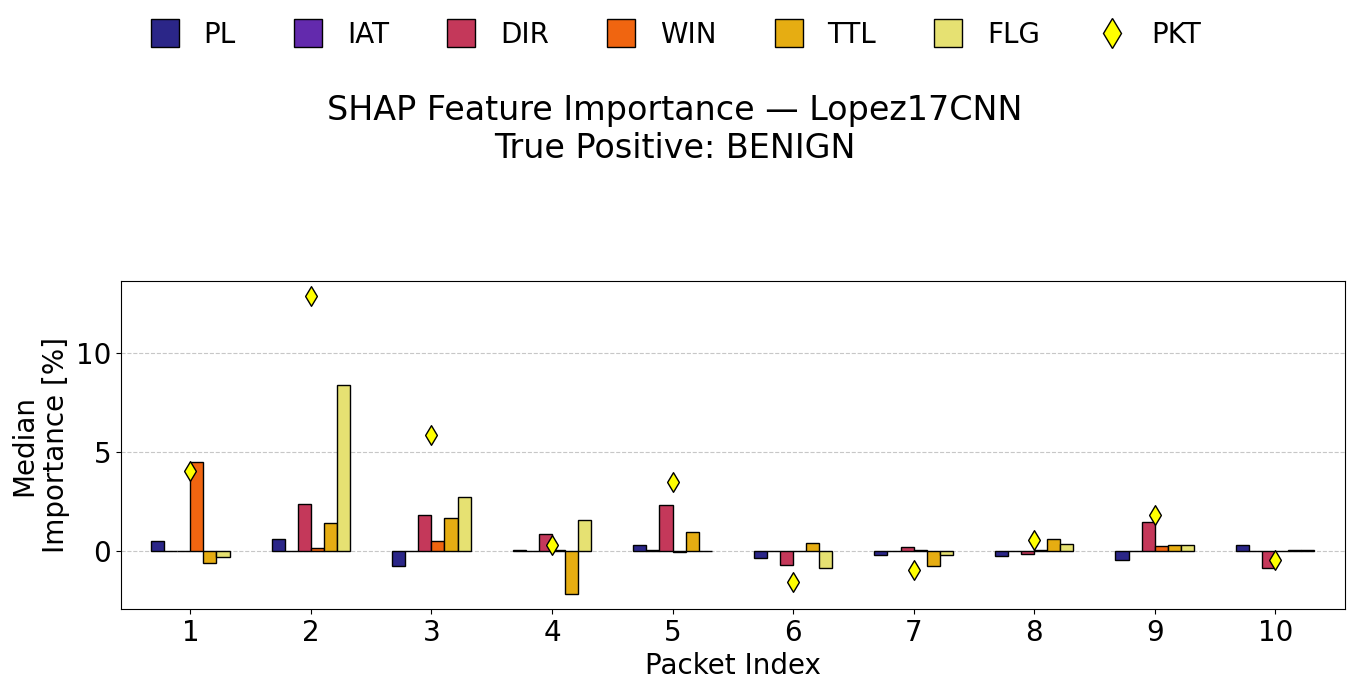

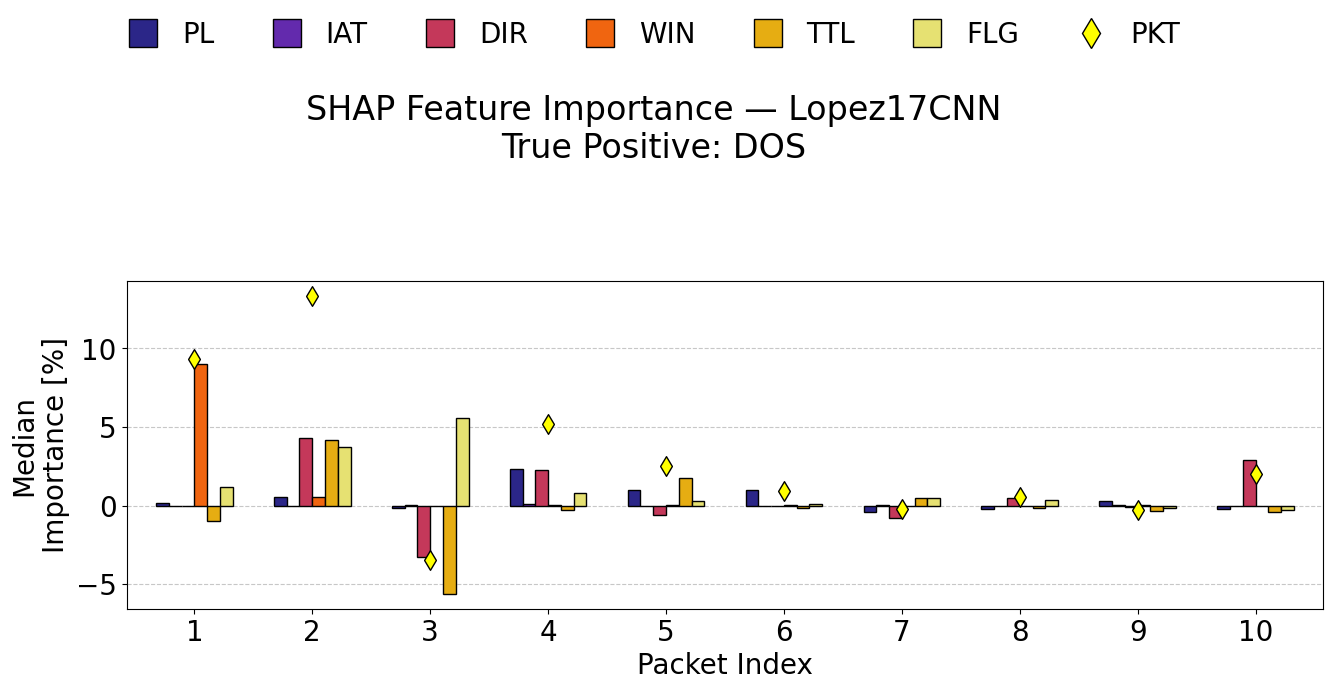

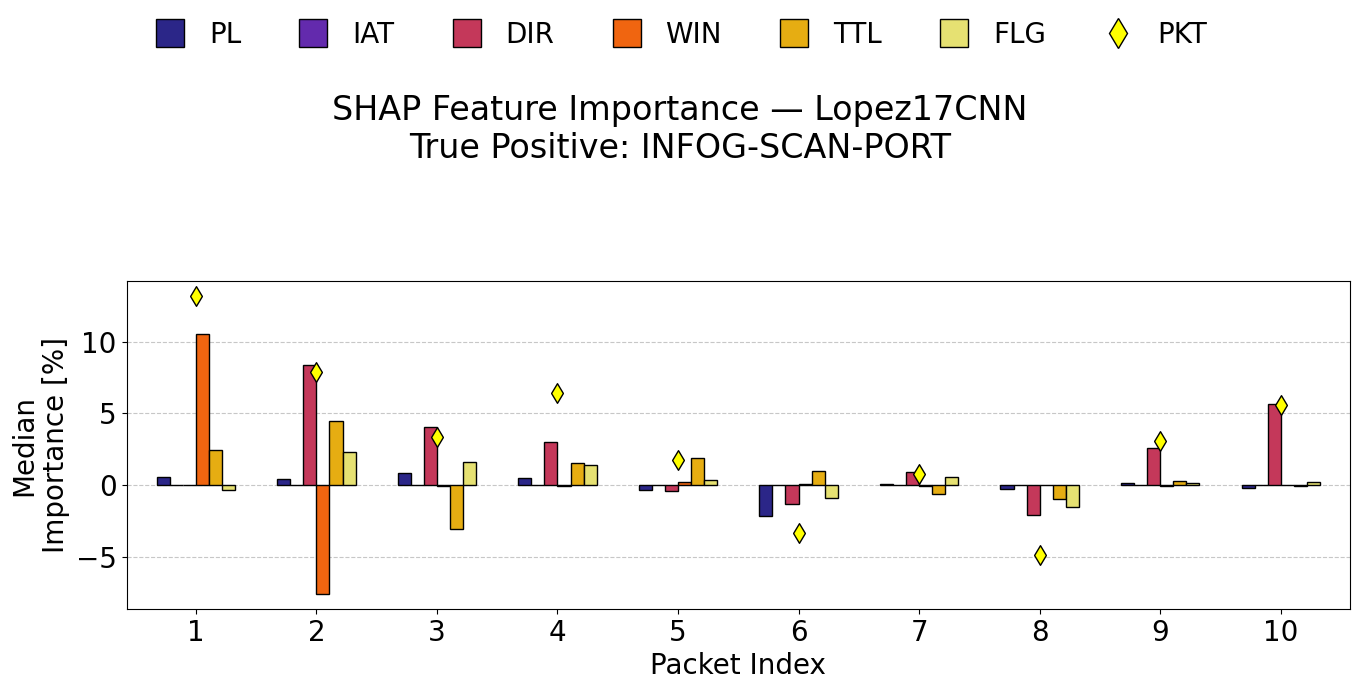

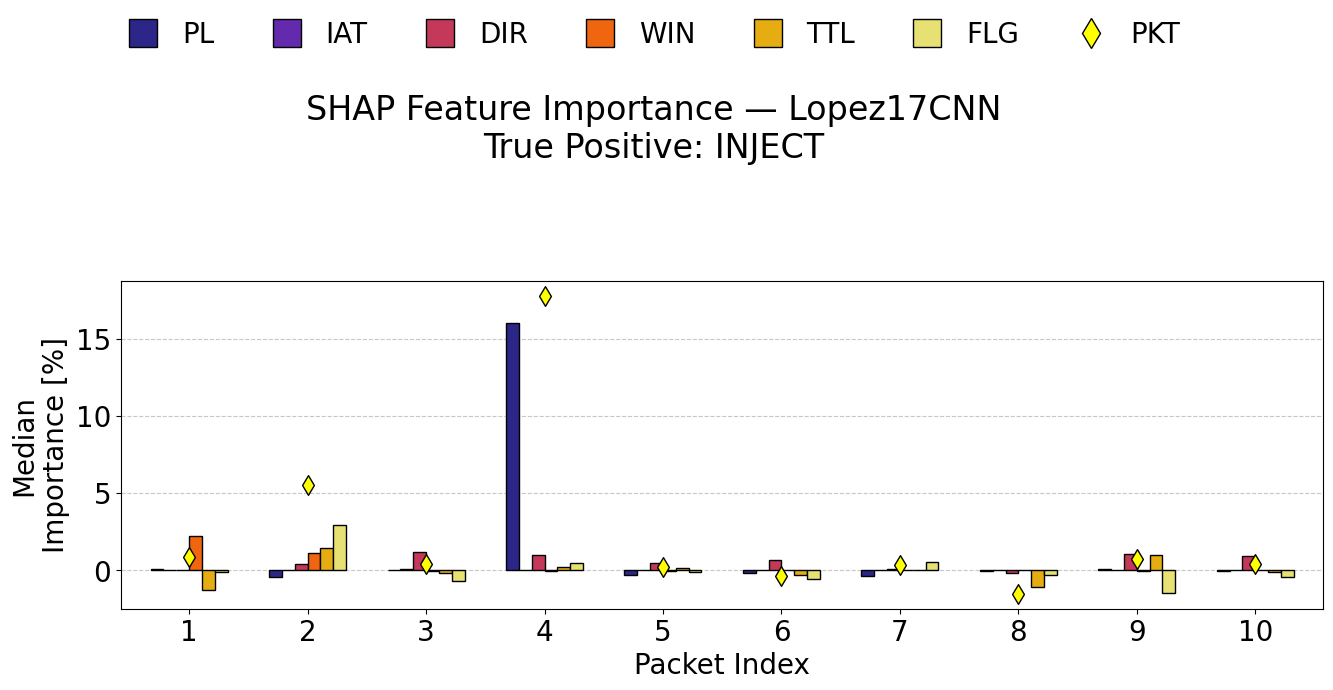

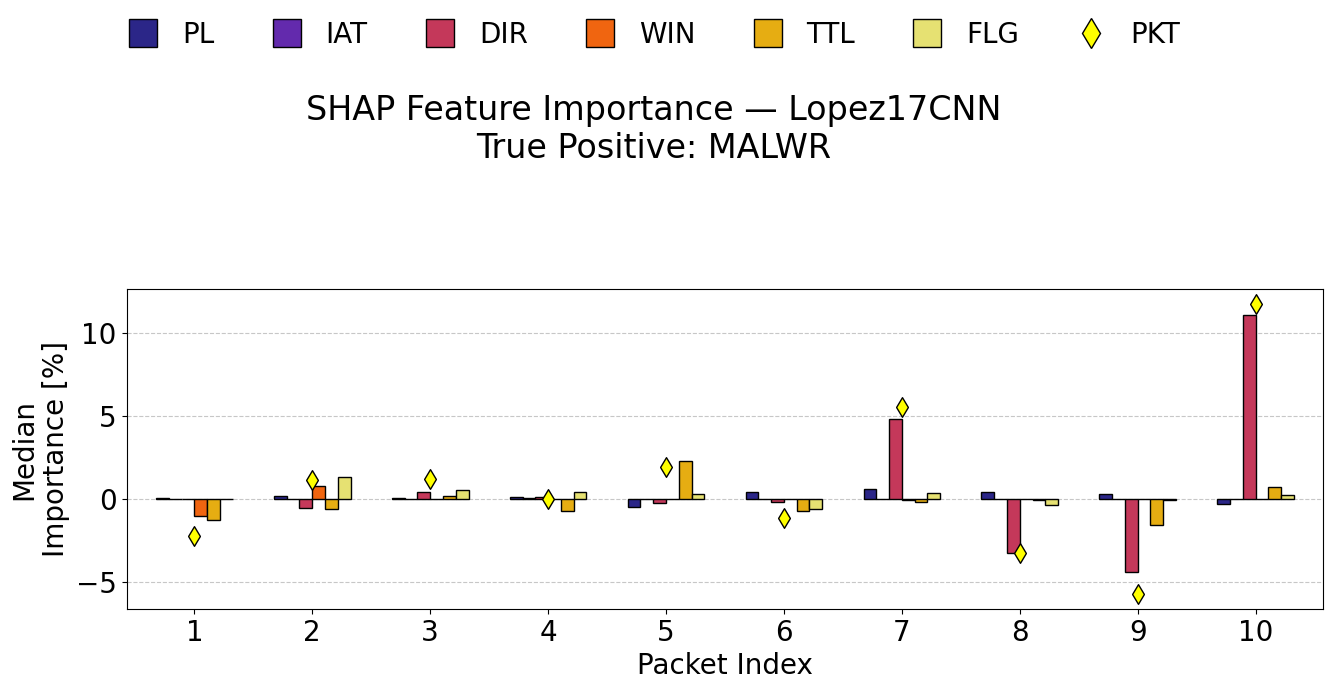

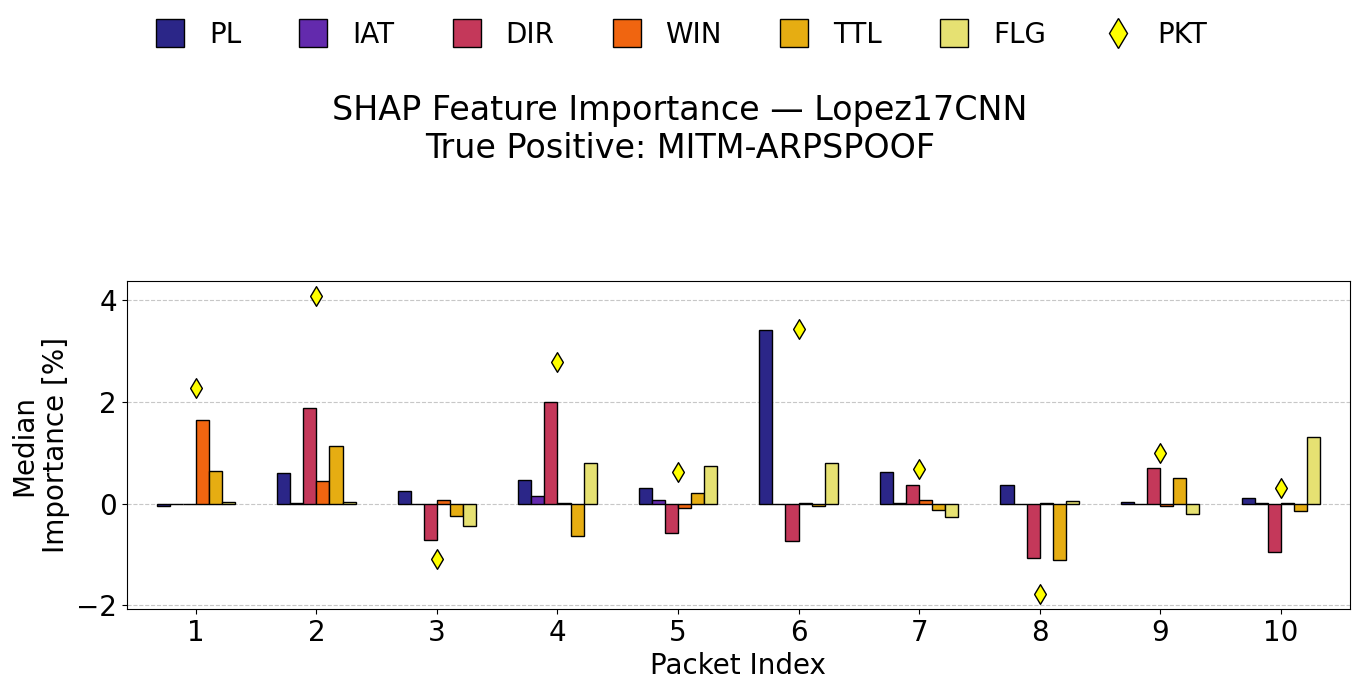

Grafici SHAP — BiflowTransformer


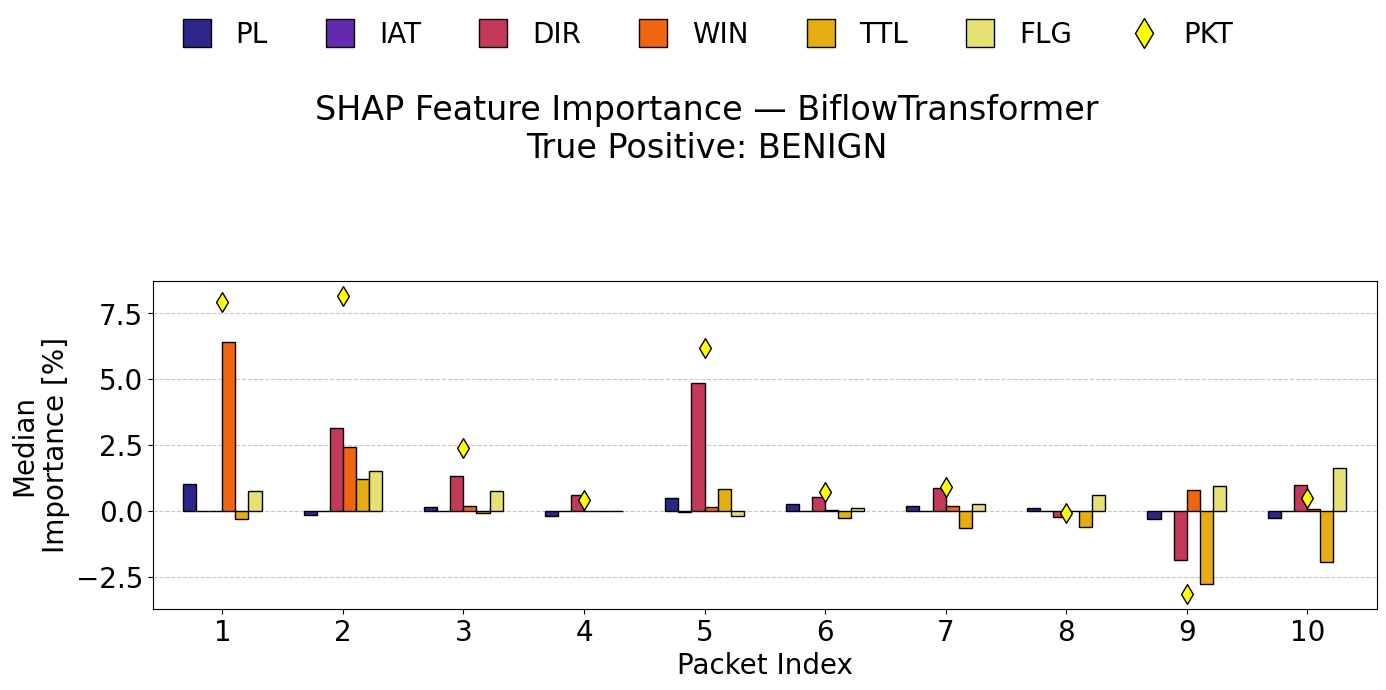

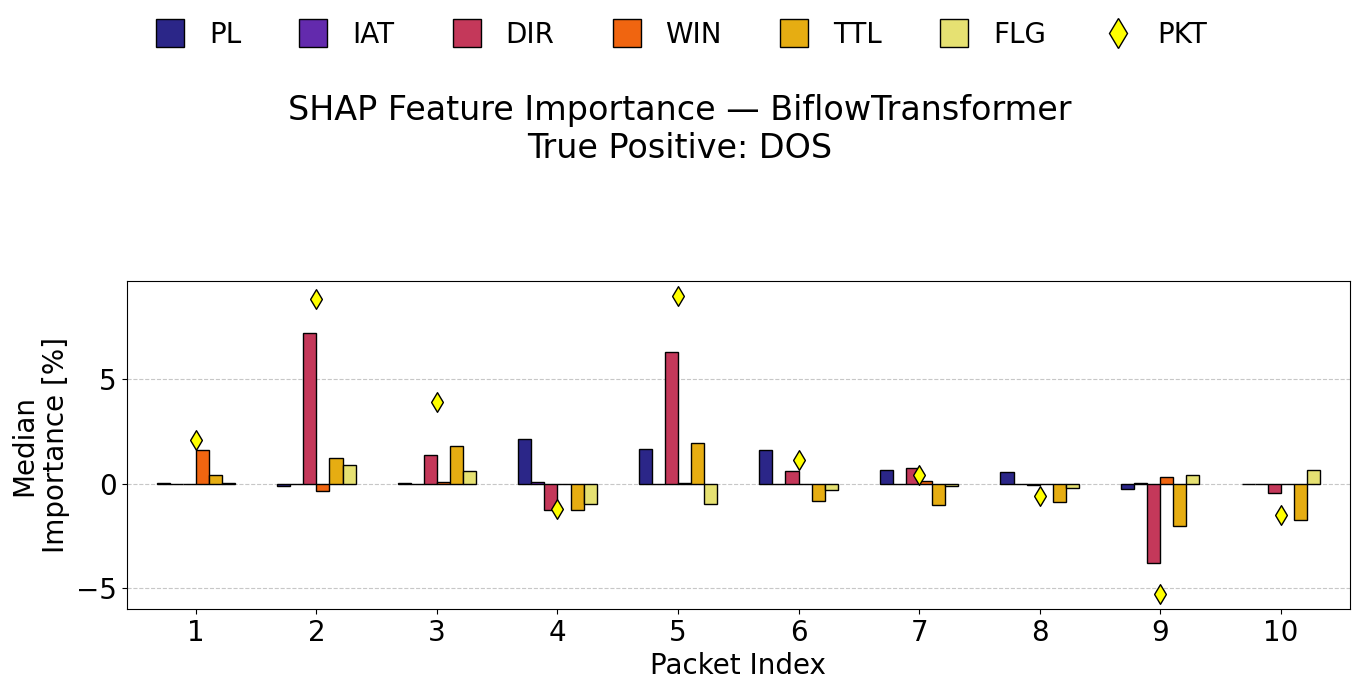

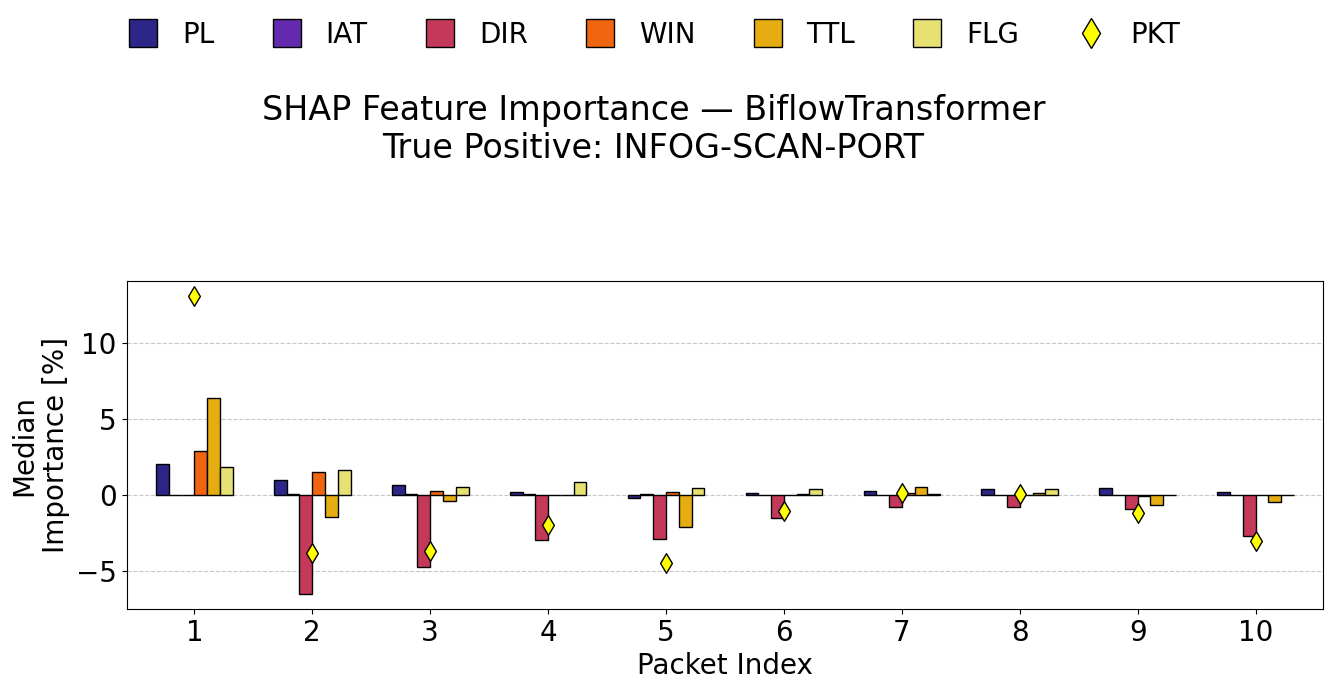

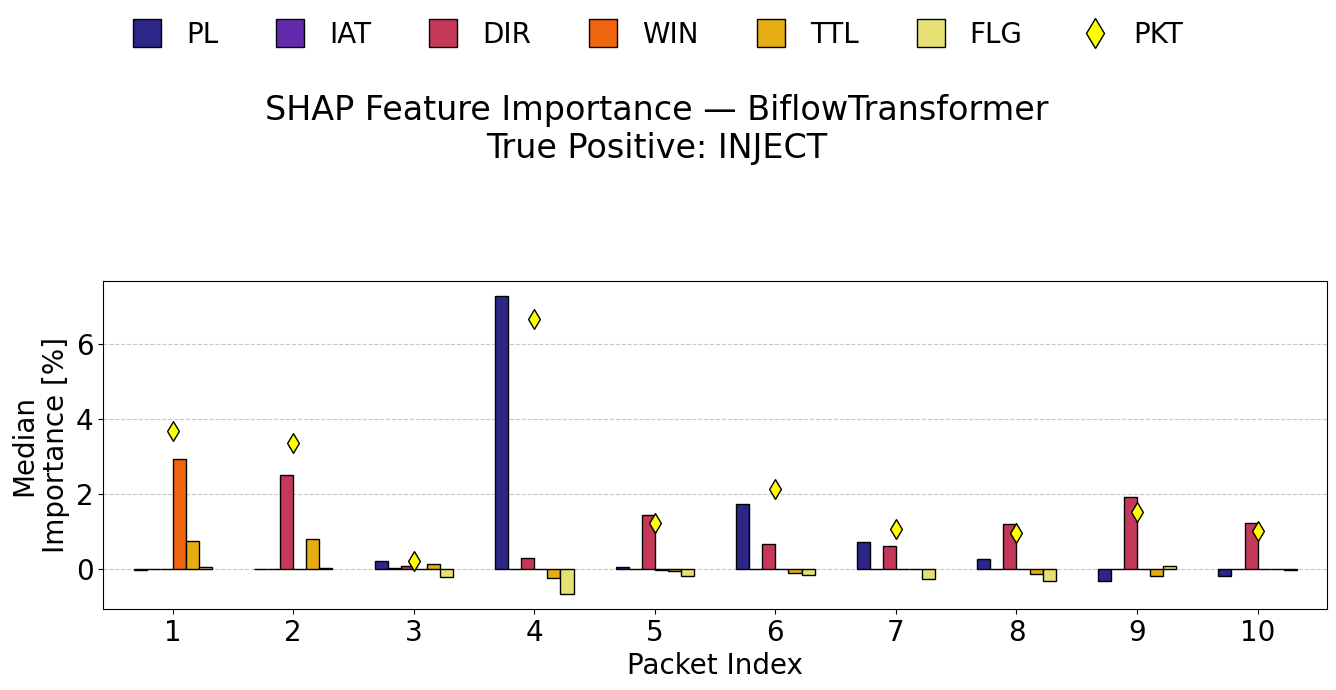

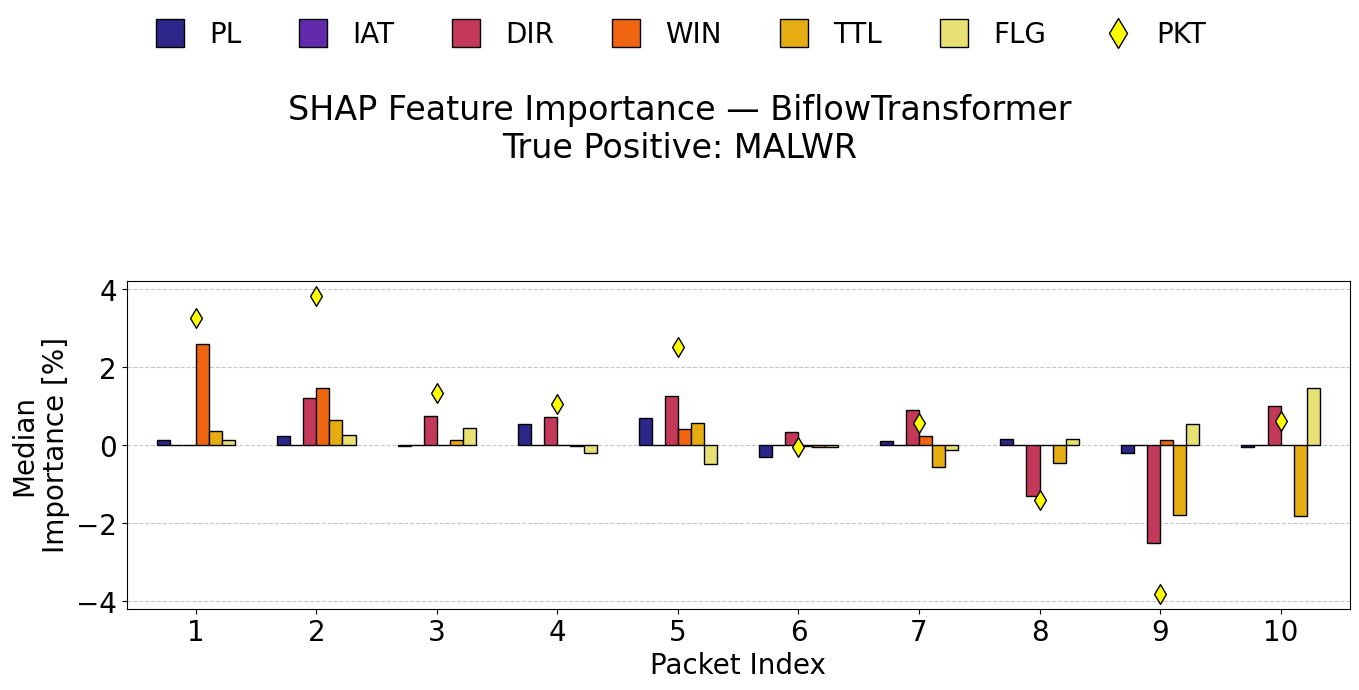

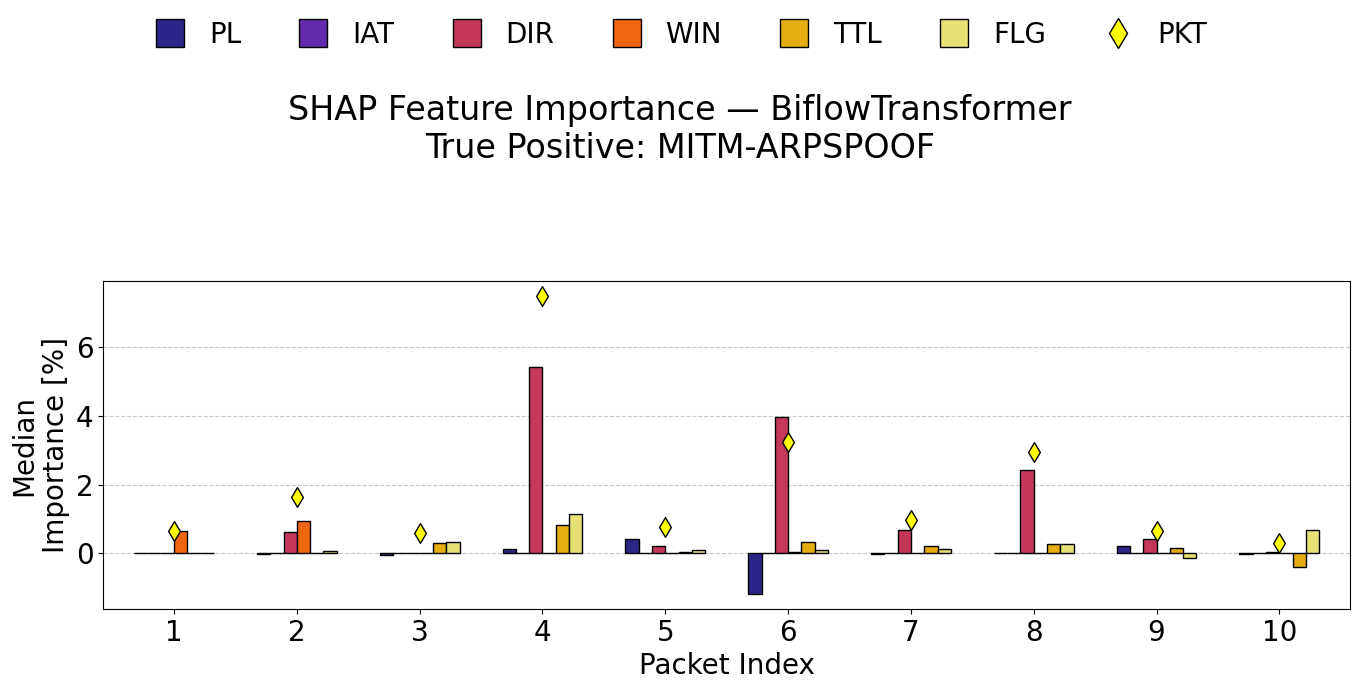

Grafici SHAP — NetMamba


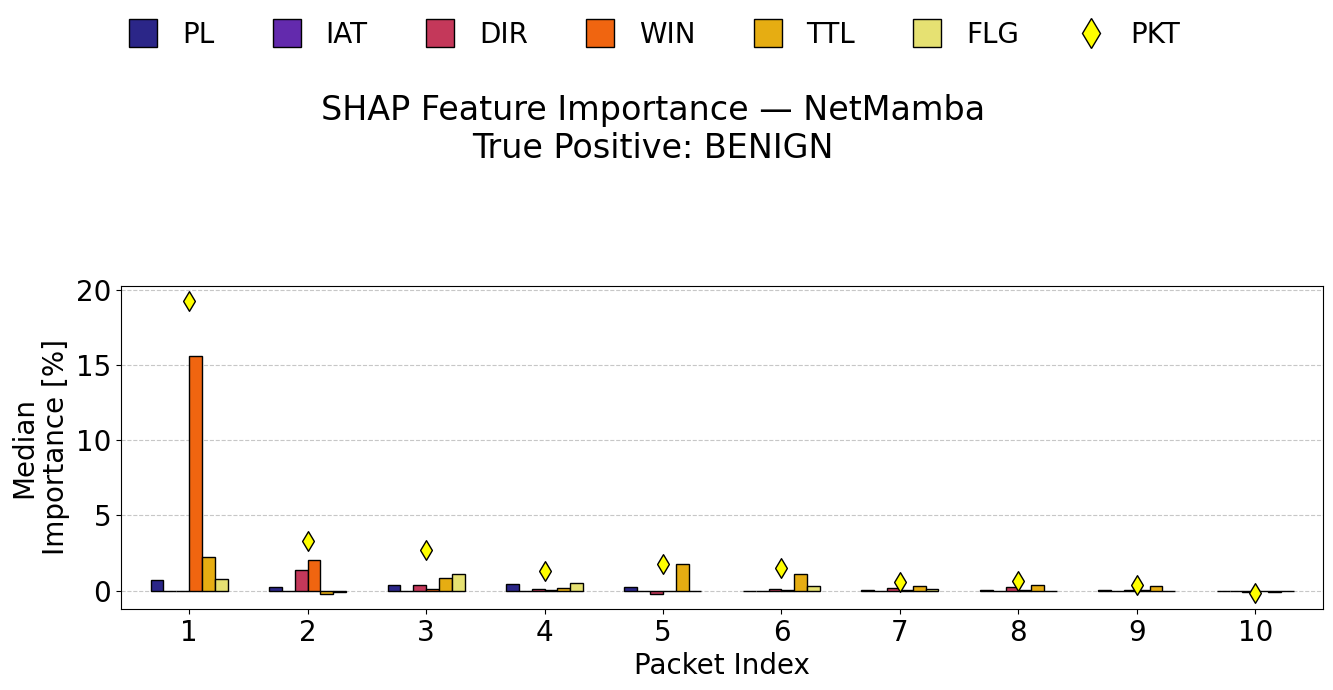

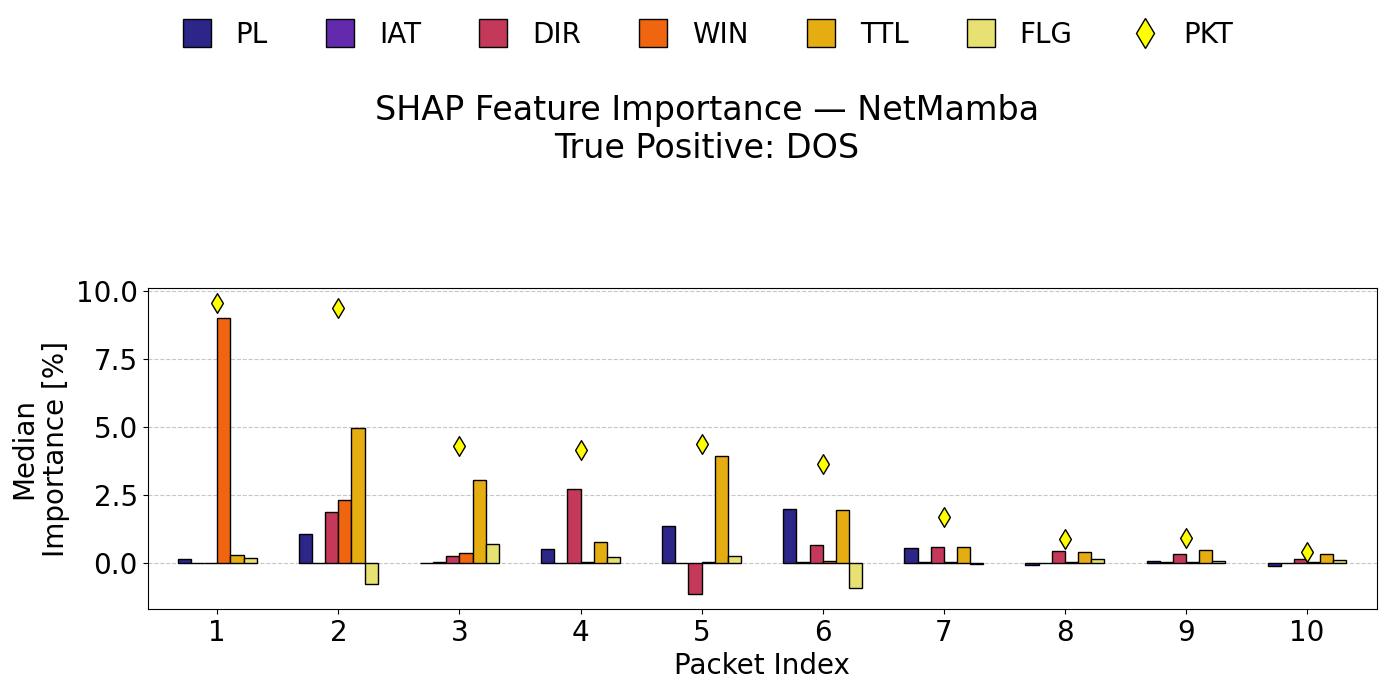

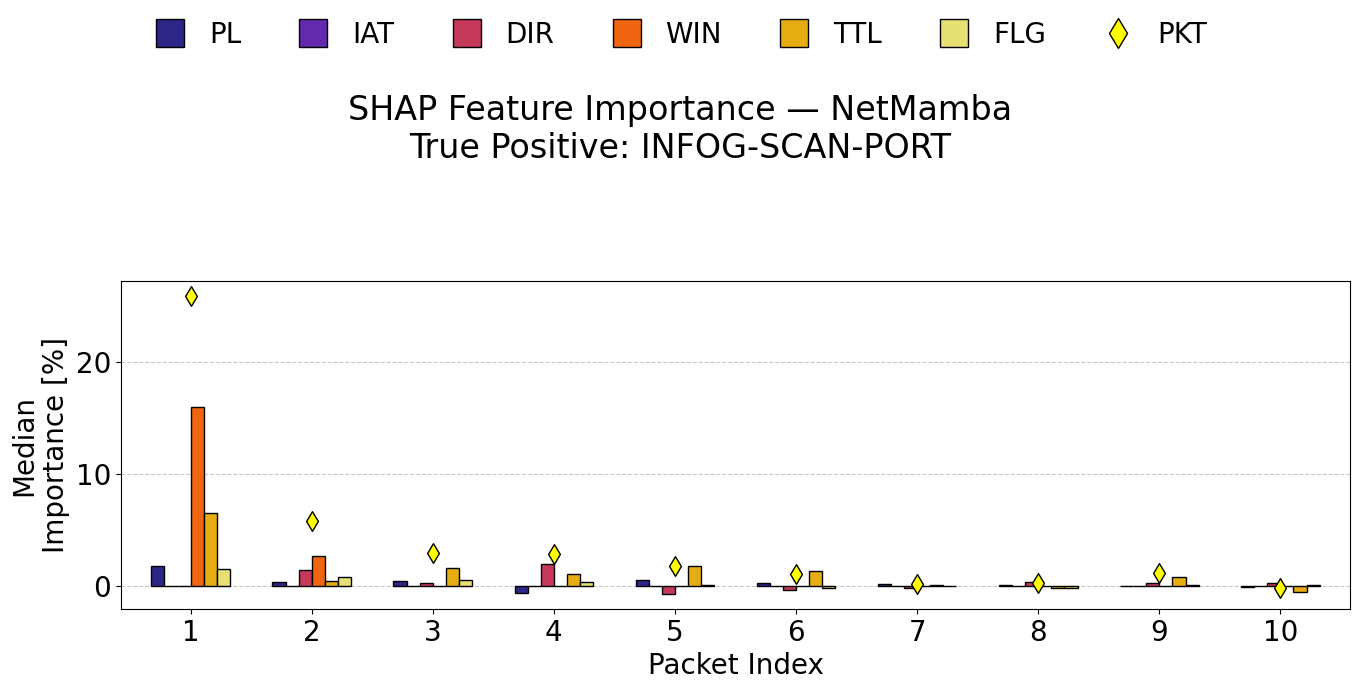

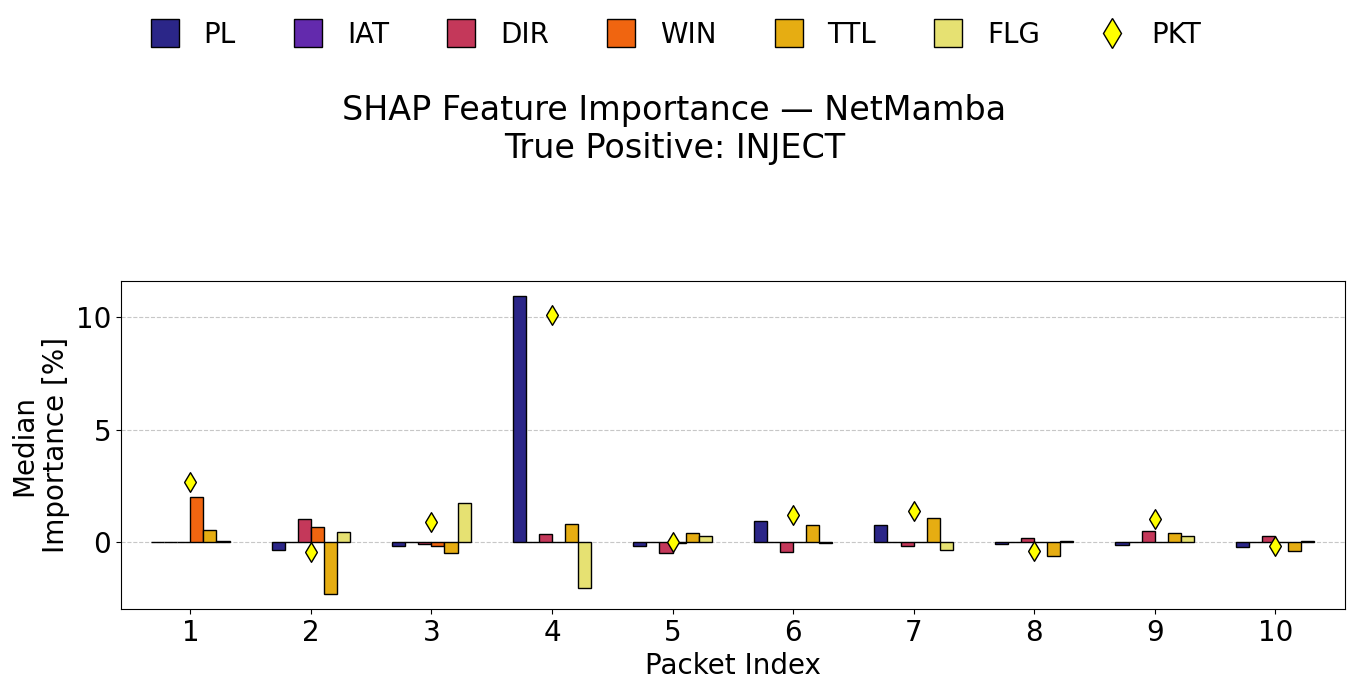

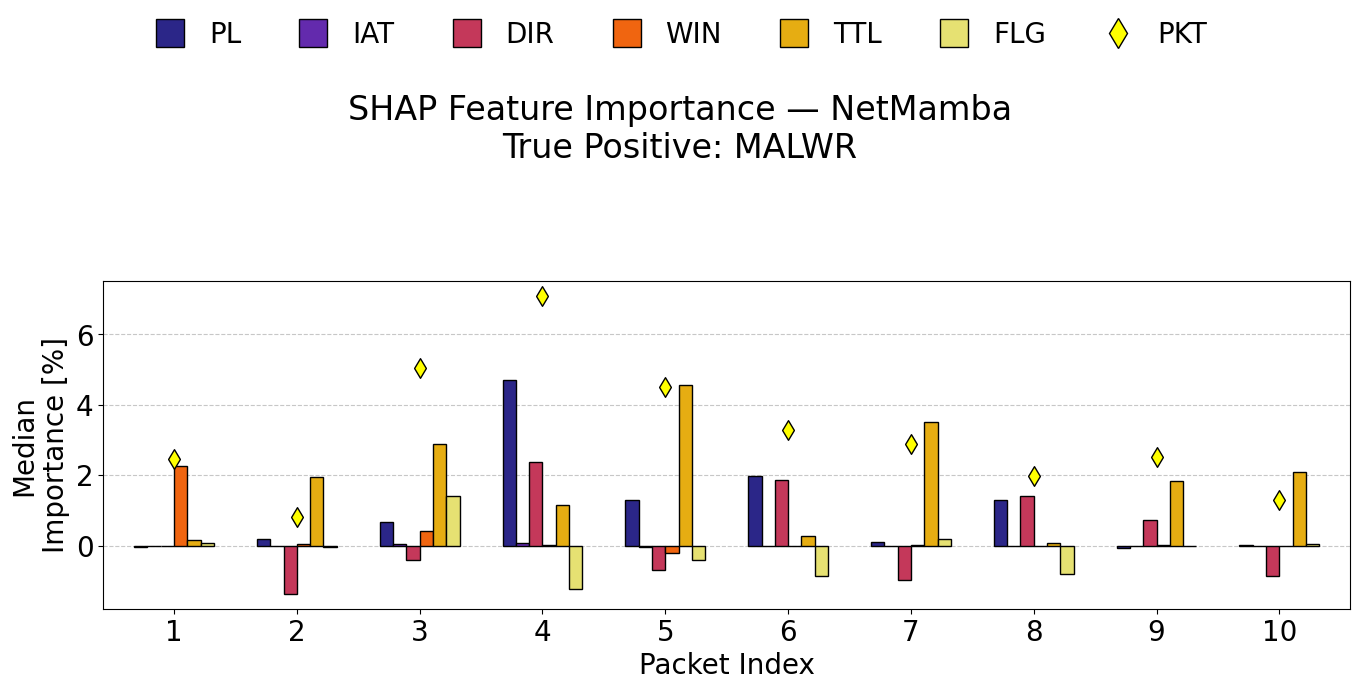

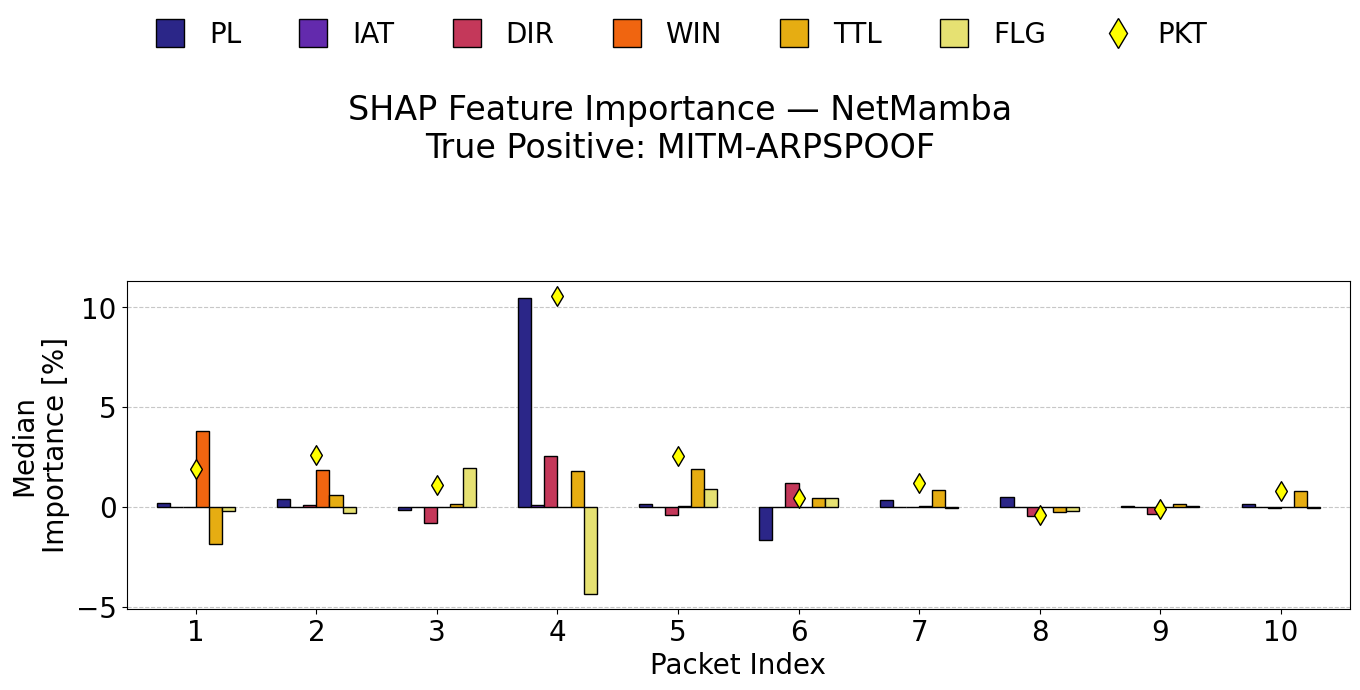

In [16]:

plt.rcParams['font.size'] = 20


def make_legend_elements(field_names, palette):
    elements = [
        Line2D([0], [0], marker='s', color='w', label=field_names[i],
               markerfacecolor=palette[i], markersize=20, markeredgecolor='black')
        for i in range(len(field_names))
    ]
    elements.append(
        Line2D([0], [0], marker='d', color='w', label='PKT',
               markerfacecolor='yellow', markersize=15, markeredgecolor='black')
    )
    return elements


def plot_shap_class(tag, c, outdir):
    m = MODELS[tag]
    field_names = m['field_names']
    num_pkts = m['args'].num_pkts
    palette = sn.color_palette('CMRmap', len(field_names))
    legend_elements = make_legend_elements(field_names, palette)

    nome_classe = CLASS_NAMES[c]
    if c not in MEDIAN_BIC[tag]:
        print(f'  [WARNING] nessun dato SHAP per {MODEL_DISPLAY_NAME[tag]} / {nome_classe}.')
        return

    shap_matrix = MEDIAN_BIC[tag][c] * 100
    bic_sum = np.sum(shap_matrix, axis=1)

    df = pd.DataFrame(shap_matrix, columns=field_names)

    fig, axes = plt.subplots(1, 1, sharey=True, figsize=(14, 7))
    df.plot.bar(edgecolor='black', width=0.65, ax=axes, legend=False, color=palette)

    axes.scatter(np.arange(num_pkts), bic_sum, color='yellow', s=100,
                 marker='d', edgecolor='black', zorder=3)

    fig.suptitle(
        f'SHAP Feature Importance — {MODEL_DISPLAY_NAME[tag]}\nTrue Positive: {nome_classe.upper()}',
        fontsize=24, y=0.88
    )
    fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.02),
               ncol=len(field_names) + 1, frameon=False, handlelength=1.2)

    axes.set_xlabel('Packet Index')
    axes.set_ylabel('Median\nImportance [%]')
    axes.set_xticklabels([str(x + 1) for x in range(num_pkts)], rotation=0)
    axes.grid(axis='y', linestyle='--', alpha=0.7)
    axes.set_axisbelow(True)

    plt.tight_layout(rect=[0, 0, 1, 0.80])
    nome_file = os.path.join(outdir, f'shap_importance_{nome_classe}.pdf')
    plt.savefig(nome_file, dpi=300, bbox_inches='tight')
    plt.show()


for tag in tags:
    print('=' * 70)
    print(f'Grafici SHAP — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    for c in range(NUM_CLASSES):
        plot_shap_class(tag, c, OUTDIR_MODEL[tag])


## 12. Riepilogo output

In [17]:

print('=== Riepilogo file prodotti ===\n')

print(f"Indici comuni corretti per classe : {os.path.join(OUTDIR_COMMON, 'correct_instances_common_diagonal.pickle')}")
print(f"Indici campioni usati per SHAP    : {os.path.join(OUTDIR_COMMON, 'sample_indices_used.pickle')}\n")

for tag in tags:
    outdir = OUTDIR_MODEL[tag]
    print(f'--- {MODEL_DISPLAY_NAME[tag]}  ({outdir}) ---')
    for fname in sorted(os.listdir(outdir)):
        print(f'  {fname}')
    print()


=== Riepilogo file prodotti ===

Indici comuni corretti per classe : ./shap_common/correct_instances_common_diagonal.pickle
Indici campioni usati per SHAP    : ./shap_common/sample_indices_used.pickle

--- Lopez17CNN  (./shap_lopez/) ---
  .ipynb_checkpoints
  adversarial
  correct_instances_diagonal.pickle
  shap_importance_benign.pdf
  shap_importance_dos.pdf
  shap_importance_infog-scan-port.pdf
  shap_importance_inject.pdf
  shap_importance_malwr.pdf
  shap_importance_mitm-arpspoof.pdf
  shap_values_correct_class_0_benign_lopez.pickle
  shap_values_correct_class_1_dos_lopez.pickle
  shap_values_correct_class_2_infog-scan-port_lopez.pickle
  shap_values_correct_class_3_inject_lopez.pickle
  shap_values_correct_class_4_malwr_lopez.pickle
  shap_values_correct_class_5_mitm-arpspoof_lopez.pickle

--- BiflowTransformer  (./shap_transformer/) ---
  adversarial
  correct_instances_diagonal.pickle
  shap_importance_benign.pdf
  shap_importance_dos.pdf
  shap_importance_infog-scan-port.pdf


### (Opzionale) Comprimi tutti gli output in un unico archivio zip

In [5]:

ARCHIVE_NAME = 'results_jupyterlab'

dirs_to_zip = [OUTDIR_COMMON] + list(OUTDIR_MODEL.values())
staging_dir = './_shap_unified_staging'
if os.path.exists(staging_dir):
    shutil.rmtree(staging_dir)
os.makedirs(staging_dir, exist_ok=True)

for d in dirs_to_zip:
    dst = os.path.join(staging_dir, os.path.basename(os.path.normpath(d)))
    shutil.copytree(d, dst)

shutil.make_archive(ARCHIVE_NAME, 'zip', staging_dir)
shutil.rmtree(staging_dir)

print(f'[OK] Archivio creato: {ARCHIVE_NAME}.zip')


[OK] Archivio creato: results_jupyterlab.zip


# Fase 2 - Adversarial Attacks

Questa parte va eseguita **dopo** il notebook "SHAP unificato" (sezioni 1-12): riusa
direttamente `MODELS`, `MEDIAN_BIC`, `sample_indices_used`, `common_correct_dict`,
`CLASS_NAMES`, `NUM_CLASSES`, `tags`, `OUTDIR_MODEL`, `OUTDIR_COMMON`, `device`, `SEED`.

**Non è necessario aver eseguito la cella di calcolo SHAP** (sezione "9. Calcolo SHAP",
quella con `compute_and_save_shap`): la sezione "10. Importanza percentuale (BIC)" legge
i valori SHAP direttamente dai `.pickle` su disco, quindi basta che quei file esistano già
da un'esecuzione precedente. La cella di bootstrap qui sotto verifica lo stato necessario
e, se manca solo `MEDIAN_BIC`, prova a ricostruirlo dai pickle su disco senza richiedere
il ricalcolo SHAP.

## I due campioni di istanze

Per ogni classe di attacco (1-5) e per ciascun modello, gli attacchi adversarial vengono
provati su **due insiemi di campioni distinti ma entrambi comuni ai tre modelli**:

1. **Campione SHAP** (`sample_indices_used`): esattamente gli stessi campioni usati per il
   calcolo dei valori SHAP nella Parte 1.
2. **Campione random** (`sample_indices_random`, costruito in questa Parte 2): fino a 200
   campioni per classe, presi dall'insieme `common_correct_dict` (corretti per tutti e tre
   i modelli) **esclusi** quelli già usati per SHAP. Se per una classe non bastano 200
   campioni "nuovi", se ne usano meno; se non ce ne sono affatto, si ricade sugli stessi
   indici del campione SHAP (con una nota esplicita nei log).

## Vincoli fisici generali (validi in *tutti* gli esperimenti)

```python
ATTACK_MIN_MAX = {
    'PL':  (1, 1500),
    'IAT': (0.0001, 60000),
    'DIR': (0, 1),
    'WIN': (1, 65535),
    'TTL': (0, 255),
}
```

- `PL` assume solo valori **interi**.
- `WIN` e `TTL` sono incrementabili/decrementabili, vincolati a `[min, max]`, e per
  realismo vengono sempre "agganciati" (snap) al valore intero osservato più vicino nel
  training set (stesso approccio dei notebook originali).
- `DIR` e `FLG` **non sono mai modificabili**.
- Se una feature ha valore fisico `-1` (padding/assente) **non viene mai toccata** ed è
  saltata.

## Esperimenti implementati

## Esperimenti implementati

## Esperimenti implementati

| # | Nome | Selezione delle feature | Obiettivo | Vincoli | Ricerca dei valori |
|---|------|--------------------------|-----------|---------|--------------------|
| 0 | Random 3-feature | Selezione casuale di 3 packet-feature pairs ammissibili | Successo se la predizione cambia verso qualunque classe diversa da quella originale, provando anche la classe benigna | Loose: solo vincoli generali su feature modificabili, range fisici e padding | Fino a 1000 scelti casualmente |
| 0.1 | Random 3-feature baseline | Selezione casuale di 3 packet-feature pairs ammissibili, ripetuta su 10 round indipendenti | Untargeted: successo se la predizione cambia verso qualunque classe diversa da quella originale | Loose: solo vincoli generali su feature modificabili, range fisici e padding | Fino a 1000 valori per feature, esplorando incrementi e decrementi rispetto al valore originale |
| 1.1 | SHAP-guided untargeted | Top-3 packet-feature pairs secondo la SHAP della classe d’attacco/originale | Untargeted: successo se la predizione cambia verso qualunque classe diversa da quella originale | Loose: solo vincoli generali su feature modificabili, range fisici e padding | Fino a 1000 valori per feature, esplorando incrementi e decrementi rispetto al valore originale |
| 1.2 | Benign-guided targeted | Top-3 packet-feature pairs secondo la SHAP della classe benign | Targeted: successo solo se la predizione diventa benign | Loose: solo vincoli generali su feature modificabili, range fisici e padding | Fino a 1000 valori per feature, esplorando incrementi e decrementi rispetto al valore originale |
| 2.1 | SHAP-guided untargeted strict | Top-3 packet-feature pairs secondo la SHAP della classe d’attacco/originale | Untargeted: successo se la predizione cambia verso qualunque classe diversa da quella originale | Strict: solo pacchetti con `DIR == 0`; PL e IAT solo crescenti | Fino a 1000 valori per feature, con ricerca limitata dai vincoli strict |
| 2.2 | Benign-guided targeted strict | Top-3 packet-feature pairs secondo la SHAP della classe benign | Targeted: successo solo se la predizione diventa benign | Strict: solo pacchetti con `DIR == 0`; PL e IAT solo crescenti | Fino a 1000 valori per feature, con ricerca limitata dai vincoli strict |
| 3.1 | Attack-class-guided targeted | Top-3 packet-feature pairs secondo la SHAP della classe d’attacco/originale | Targeted: successo solo se la predizione diventa benign | Loose: solo vincoli generali su feature modificabili, range fisici e padding | Fino a 1000 valori per feature, esplorando incrementi e decrementi rispetto al valore originale |
| 3.2 | Attack-class-guided targeted strict | Top-3 packet-feature pairs secondo la SHAP della classe d’attacco/originale | Targeted: successo solo se la predizione diventa benign | Strict: solo pacchetti con `DIR == 0`; PL e IAT solo crescenti | Fino a 1000 valori per feature, con ricerca limitata dai vincoli strict |


Tutti i risultati vengono salvati in JSON (stesso stile `NumpyEncoder` dei notebook
originali) dentro `adversarial_<modello>/`, più un riepilogo aggregato in `adversarial_common/`.


## 0. Bootstrap

In [18]:

import os
import json
import pickle
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
from tqdm import tqdm

# Funzione di normalizzazione del framework (usata per riportare i campioni perturbati
# dal dominio fisico al dominio [0,1] atteso dai modelli)
from datasets.networking_dataset import normalize as dataset_normalize

REQUIRED_GLOBALS = ['MODELS', 'CLASS_NAMES', 'NUM_CLASSES', 'tags', 'OUTDIR_MODEL',
                     'OUTDIR_COMMON', 'device', 'SEED', 'sample_indices_used',
                     'common_correct_dict', 'MODEL_DISPLAY_NAME']

missing = [g for g in REQUIRED_GLOBALS if g not in globals()]
if missing:
    raise RuntimeError(
        '[ERRORE] Mancano queste variabili nel kernel: ' + ', '.join(missing) + '.\n'
        'Esegui prima le sezioni 1-8 (e 10) del notebook "SHAP unificato": NON è '
        'necessario rieseguire la sezione 9 (calcolo SHAP), ma le altre devono girare.'
    )

# MEDIAN_BIC: se manca, prova a ricostruirlo dai pickle su disco (richiede solo che i
# file SHAP siano già stati salvati in una run precedente, non che la cella 9 sia stata
# eseguita in QUESTA sessione).
if 'MEDIAN_BIC' not in globals() or not all(MEDIAN_BIC.get(t) for t in tags):
    print('[INFO] MEDIAN_BIC assente o incompleto: provo a ricostruirlo dai .pickle su disco...')

    def _get_shap_for_class(shap_values, class_idx):
        if isinstance(shap_values, list):
            return shap_values[class_idx]
        return shap_values[..., class_idx]

    def _compute_median_bic(tag, outdir, num_classes):
        m = MODELS[tag]
        out = {}
        for c in range(num_classes):
            nome_classe = CLASS_NAMES[c]
            shap_filename = os.path.join(
                outdir, f'shap_values_correct_class_{c}_{nome_classe}_{tag}.pickle'
            )
            if not os.path.exists(shap_filename):
                print(f'  [WARNING] file SHAP non trovato per {MODEL_DISPLAY_NAME[tag]} / '
                      f'{nome_classe.upper()}: {shap_filename}')
                continue
            with open(shap_filename, 'rb') as f_in:
                saved = pickle.load(f_in)
            shap_values = saved['shap_values']
            instance_shape = saved['instance_shape']
            neurone_idx = m['argsort'][c]
            array_flat = _get_shap_for_class(shap_values, neurone_idx)
            num_campioni = array_flat.shape[0]
            array_shaps = array_flat.reshape((num_campioni,) + instance_shape)
            bic_corrente = []
            for i in range(num_campioni):
                matrice_shap = array_shaps[i][0]
                denom = np.sum(np.abs(matrice_shap))
                if denom == 0:
                    denom = 1e-8
                bic_corrente.append(matrice_shap / denom)
            out[c] = np.median(np.array(bic_corrente), axis=0)
        return out

    MEDIAN_BIC = {t: _compute_median_bic(t, OUTDIR_MODEL[t], NUM_CLASSES) for t in tags}

for t in tags:
    n_classes_ok = len(MEDIAN_BIC.get(t, {}))
    print(f'[OK] MEDIAN_BIC[{t}]: {n_classes_ok}/{NUM_CLASSES} classi disponibili')
    if n_classes_ok < NUM_CLASSES:
        print(f'  [WARNING] Per {MODEL_DISPLAY_NAME[t]} mancano valori SHAP per alcune '
              'classi: gli esperimenti guidati da SHAP (1.1, 1.2, 2) salteranno quelle classi.')

print('\n[OK] Stato verificato, si può procedere con la Parte 2.')


[OK] MEDIAN_BIC[lopez]: 6/6 classi disponibili
[OK] MEDIAN_BIC[transformer]: 6/6 classi disponibili
[OK] MEDIAN_BIC[netmamba]: 6/6 classi disponibili

[OK] Stato verificato, si può procedere con la Parte 2.


## 0bis. Configurazione esperimenti adversarial

In [19]:

# ----------------------------------------------------------------------------
# Vincoli fisici per la generazione/clamping dei candidati di attacco
# ----------------------------------------------------------------------------
ATTACK_MIN_MAX = {
    'PL':  (1, 1500),
    'IAT': (0.0001, 60000),
    'DIR': (0, 1),
    'WIN': (1, 65535),
    'TTL': (0, 255),
}
MODIFIABLE_FIELD_NAMES = ['PL', 'IAT', 'WIN', 'TTL']   # DIR e FLG esclusi sempre

# ----------------------------------------------------------------------------
# Classi su cui girano gli esperimenti adversarial: solo le classi di attacco (1-5),
# stessa convenzione dei notebook originali (Esperimenti A-E non toccavano BENIGN=0).
# ----------------------------------------------------------------------------
ATTACK_CLASSES = list(range(1, NUM_CLASSES))

# ----------------------------------------------------------------------------
# Parametri dei singoli esperimenti
# ----------------------------------------------------------------------------
TOP_K_FEATURES        = 3
MAX_ATTEMPTS           = 1000   # esperimenti 1.1, 1.2, 2
N_ROUNDS_EXP0          = 10
MAX_ATTEMPTS_EXP0      = 1000

N_SAMPLES_RANDOM_SOURCE = 200   # campioni "random" per classe (secondo campione)

# ----------------------------------------------------------------------------
# QUICK_TEST_LIMIT: se diverso da None, limita il numero di campioni per classe usati
# in OGNI esperimento, per fare un giro di prova veloce prima del run completo.
# Impostalo a None per usare tutti i campioni disponibili (fino a 200/classe).
# ----------------------------------------------------------------------------
QUICK_TEST_LIMIT = None   # es. 10 per un test rapido

# ----------------------------------------------------------------------------
# Cartelle di output
# ----------------------------------------------------------------------------
OUTDIR_ADV = {t: os.path.join(OUTDIR_MODEL[t], 'adversarial') for t in tags}
OUTDIR_ADV_COMMON = os.path.join(OUTDIR_COMMON, 'adversarial_common')
for d in list(OUTDIR_ADV.values()) + [OUTDIR_ADV_COMMON]:
    os.makedirs(d, exist_ok=True)

SAMPLE_SOURCES = ['shap', 'random']   # ordine fisso usato ovunque

# Log di osservazioni interessanti/anomalie raccolte durante l'esecuzione
INTERESTING_NOTES = []

def log_note(msg):
    print(f'[NOTE] {msg}')
    INTERESTING_NOTES.append(msg)

print('[INFO] Configurazione adversarial caricata.')
print(f'  ATTACK_MIN_MAX = {ATTACK_MIN_MAX}')
print(f'  ATTACK_CLASSES = {ATTACK_CLASSES}')
print(f'  MAX_ATTEMPTS={MAX_ATTEMPTS} | N_ROUNDS_EXP0={N_ROUNDS_EXP0} | '
      f'MAX_ATTEMPTS_EXP0={MAX_ATTEMPTS_EXP0} | TOP_K_FEATURES={TOP_K_FEATURES}')


[INFO] Configurazione adversarial caricata.
  ATTACK_MIN_MAX = {'PL': (1, 1500), 'IAT': (0.0001, 60000), 'DIR': (0, 1), 'WIN': (1, 65535), 'TTL': (0, 255)}
  ATTACK_CLASSES = [1, 2, 3, 4, 5]
  MAX_ATTEMPTS=1000 | N_ROUNDS_EXP0=15 | MAX_ATTEMPTS_EXP0=1000 | TOP_K_FEATURES=3


## 1. Normalizzazione / denormalizzazione fisica

`unnormalize_instances` riporta i tensori
normalizzati `[0,1]` ai valori fisici (usando i bound storici del framework, compreso il
sentinel `-1` per il padding); `normalize_sample` fa il percorso inverso usando la
funzione `normalize` del dataset, in modo che il modello riceva input nello stesso
formato visto in training.

In [20]:

# Bound storici usati dal framework per il roundtrip normalizzato <-> fisico
# (NON sono i bound dell'attacco: servono solo a ricostruire correttamente i valori fisici,
# incluso il sentinel -1 di padding, esattamente come nei notebook originali).
UNNORM_MIN_MAX = {
    'PL': (-1, 1500), 'IAT': (-1, 60000), 'DIR': (-1, 1), 'LOAD': (-1, 255),
    'WIN': (-1, 65535), 'FLG': (-1, 255), 'TTL': (-1, 255), 'PORT_CAT': (-1, 2)
}


def normalize_sample(sample_raw, fields):
    '''Converte un campione fisico (num_pkts, len(fields)) — o con batch dim (1, num_pkts,
    len(fields)) — nel dominio normalizzato [0,1] atteso dal modello.'''
    squeeze = (sample_raw.ndim == 3)
    x = sample_raw.squeeze(0) if squeeze else sample_raw.copy()
    x = x.copy().astype(np.float64)
    num_pkts = x.shape[0]
    for fi, field in enumerate(fields):
        col = x[:, fi]
        x[:, fi] = dataset_normalize(col, num_pkts, field)
    x = x.astype(np.float32)
    return x[np.newaxis] if squeeze else x


def unnormalize_instances(instances, fields):
    '''Converte un batch di istanze normalizzate [0,1] (N, 1, num_pkts, len(fields)) nei
    valori fisici originali, preservando il sentinel -1 di padding.'''
    raw_arr = instances.numpy().copy() if isinstance(instances, torch.Tensor) else np.array(instances).copy()
    for fi, field in enumerate(fields):
        min_val, max_val = UNNORM_MIN_MAX[field]
        if raw_arr.ndim == 4:
            raw_arr[:, 0, :, fi] = raw_arr[:, 0, :, fi] * (max_val - min_val) + min_val
        elif raw_arr.ndim == 3:
            raw_arr[:, :, fi] = raw_arr[:, :, fi] * (max_val - min_val) + min_val
    return np.round(raw_arr, decimals=4)


print('[OK] Funzioni di normalizzazione/denormalizzazione caricate.')


[OK] Funzioni di normalizzazione/denormalizzazione caricate.


## 2. Contesto adversarial per modello (`AdvContext`)

Una classe che raccoglie, per un singolo modello, tutto il necessario per generare e
valutare perturbazioni nel dominio fisico: dati raw (train/test), funzioni di
clamping/candidati/predizione. Tutte le feature modificabili (`PL`, `IAT`, `WIN`, `TTL`)
sono trattate come grandezze **intere** (o continua per `IAT`) e perturbate con
incrementi/decrementi a passo fisico minimo entro i limiti di `ATTACK_MIN_MAX`. Il contesto viene costruito una volta per modello e riusato da tutti gli esperimenti.

In [29]:

class AdvContext:
    def __init__(self, tag):
        m = MODELS[tag]
        self.tag = tag
        self.model = m['scratch_model']
        self.class_order = m['class_order']
        self.argsort = m['argsort']
        self.field_names = m['field_names']
        self.field_idx = {f: i for i, f in enumerate(self.field_names)}
        self.num_pkts = m['args'].num_pkts
        self.modifiable_fields = [self.field_idx[f] for f in MODIFIABLE_FIELD_NAMES
                                   if f in self.field_idx]

        print(f'[INFO] Denormalizzazione train/test set fisico per {MODEL_DISPLAY_NAME[tag]}...')
        self.trn_raw = unnormalize_instances(m['trn_instances'], self.field_names)
        self.tst_raw = unnormalize_instances(m['tst_instances'], self.field_names)
        self.trn_targets_true = m['trn_targets_true']

        self.benign_neuron_idx = int(self.argsort[0])
        self.dir_idx = self.field_idx.get('DIR', None)
        self.pl_idx = self.field_idx.get('PL', None)

        
    def predict_canonical_batch(self, samples_raw_list): 
        '''samples_raw_list: lista di array (num_pkts, len(fields)) in dominio fisico.
        Una sola forward pass per l'intero batch.'''
        normed = [normalize_sample(s, self.field_names) for s in samples_raw_list]
        batch = np.stack(normed, axis=0)                              # (B, num_pkts, len(fields))
        x = torch.from_numpy(batch).float().unsqueeze(1).to(device)   # (B, 1, num_pkts, len(fields))
        with torch.no_grad():
            probs = self.model(x).cpu().numpy()                      # (B, num_classes)
        neuron_idx = probs.argmax(axis=1)
        canon = np.array([self.class_order[i] for i in neuron_idx])
        return canon, probs


    def predict_canonical(self, sample_raw):
        '''sample_raw: (num_pkts, len(fields)) in dominio fisico. Ritorna (classe_canonica, probs).'''
        sample_norm = normalize_sample(sample_raw, self.field_names)
        # sample_norm: (num_pkts, len(fields)) -> serve (batch=1, channel=1, num_pkts, len(fields))
        x = torch.from_numpy(sample_norm).float().unsqueeze(0).unsqueeze(0).to(device)
        with torch.no_grad():
            probs = self.model(x).cpu().numpy()[0]
        neuron_idx = int(np.argmax(probs))
        return self.class_order[neuron_idx], probs

    def is_feature_absent(self, sample_raw, pkt, fi):
        if self.pl_idx is not None and sample_raw[pkt, self.pl_idx] == -1.0:
            return True
        return sample_raw[pkt, fi] == -1.0

    def clamp(self, value, fi):
        field = self.field_names[fi]
        value = float(value)
        if field in ('PL', 'WIN', 'TTL'):
            value = round(value)
        lo, hi = ATTACK_MIN_MAX.get(field, (-np.inf, np.inf))
        return float(np.clip(value, lo, hi))

    def random_value(self, fi, rng):
        field = self.field_names[fi]
        lo, hi = ATTACK_MIN_MAX[field]
        if field in ('PL', 'WIN', 'TTL'):
            v = rng.integers(int(np.ceil(lo)), int(np.floor(hi)) + 1)
        else:  # IAT (continua)
            v = rng.uniform(lo, hi)
        return self.clamp(v, fi)

    def get_top_k_features(self, shap_matrix, k=3, sign='abs'):
        '''sign='abs' (default, comportamento originale): ranking per |SHAP|.
        sign='positive': considera solo le feature con SHAP > 0 (quelle che
        sostengono la classe di riferimento), ordinate per valore decrescente.
        sign='negative': simmetrico, solo SHAP < 0.'''
        if sign == 'positive':
            importance = np.where(shap_matrix > 0, shap_matrix, -np.inf)
        elif sign == 'negative':
            importance = np.where(shap_matrix < 0, -shap_matrix, -np.inf)
        else:
            importance = np.abs(shap_matrix)
 
        mask = np.zeros((self.num_pkts, len(self.field_names)), dtype=bool)
        for fi in self.modifiable_fields:
            mask[:, fi] = True
        importance = np.where(mask, importance, -np.inf)
 
        flat_order = np.argsort(importance.ravel())[::-1]
        top_k = []
        for idx in flat_order:
            pkt, fi = idx // len(self.field_names), idx % len(self.field_names)
            if importance[pkt, fi] == -np.inf:
                break   # esaurite le feature valide per questo criterio
            if mask[pkt, fi]:
                top_k.append((pkt, fi))
            if len(top_k) == k:
                break
        return top_k

    def candidate_grid(self, fi, start_val, n_steps=500, only_increase=False):
        '''Griglia di candidati ottenuta perturbando start_val (valore di partenza
        reale della feature nel campione) un passo alla volta, SENZA alcuna
        conoscenza di un valore target (es. la mediana benigna, che un attaccante
        reale non conosce). Esplora entrambe le direzioni alternandole
        (+1,-1,+2,-2,...), a meno che only_increase=True (solo verso l'alto).'''
        delta = 1  # PL: 1 byte | IAT: 1 ms | WIN/TTL: 1 unità — passo fisico minimo
        out, seen = [], set()
        for s in range(1, n_steps + 1):
            v_up = self.clamp(start_val + s * delta, fi)
            if v_up not in seen:
                seen.add(v_up)
                out.append(v_up)
            if not only_increase:
                v_down = self.clamp(start_val - s * delta, fi)
                if v_down not in seen:
                    seen.add(v_down)
                    out.append(v_down)
        return out

    def feature_label(self, pkt, fi):
        return f'pkt{pkt + 1}-{self.field_names[fi]}'


print('[INFO] Costruzione del contesto adversarial per i tre modelli...')
ADV_CTX = {}
for tag in tags:
    print('=' * 70)
    print(f'AdvContext — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ADV_CTX[tag] = AdvContext(tag)
print('\n[OK] Contesti adversarial pronti per: ' + ', '.join(tags))


[INFO] Costruzione del contesto adversarial per i tre modelli...
AdvContext — Lopez17CNN
[INFO] Denormalizzazione train/test set fisico per Lopez17CNN...
AdvContext — BiflowTransformer
[INFO] Denormalizzazione train/test set fisico per BiflowTransformer...
AdvContext — NetMamba
[INFO] Denormalizzazione train/test set fisico per NetMamba...

[OK] Contesti adversarial pronti per: lopez, transformer, netmamba


## 3. Costruzione del campione "random" (secondo campione)

Per ciascuna classe, peschiamo fino a `N_SAMPLES_RANDOM_SOURCE` indici da
`common_correct_dict[c]` **esclusi** quelli già in `sample_indices_used[c]` (il campione
SHAP). Sono quindi corretti per tutti e tre i modelli, mai usati per il calcolo SHAP.
Se la disponibilità residua è inferiore a 200 si usano tutti quelli disponibili; se è
zero si ricade sugli stessi indici del campione SHAP per quella classe (loggato come nota).

In [22]:

sample_indices_random = {}
rng_random_sample = np.random.default_rng(SEED + 1)   # seed diverso da quello del campione SHAP

print('=== Costruzione campione random (comune ai 3 modelli, diverso da SHAP) ===')
for c in range(NUM_CLASSES):
    shap_idx = set(sample_indices_used.get(c, np.array([], dtype=int)).tolist())
    available = [i for i in common_correct_dict.get(c, np.array([], dtype=int)).tolist()
                 if i not in shap_idx]

    if len(available) == 0:
        chosen = np.array(sorted(shap_idx), dtype=int)
        if len(chosen) > 0:
            log_note(f"Classe {CLASS_NAMES[c].upper()}: nessun campione comune disponibile "
                      "oltre a quelli usati per SHAP -> il campione 'random' ricade sugli "
                      "stessi indici del campione SHAP per questa classe.")
        else:
            log_note(f"Classe {CLASS_NAMES[c].upper()}: nessun campione disponibile né per "
                      "SHAP né per il campione random.")
    elif len(available) > N_SAMPLES_RANDOM_SOURCE:
        chosen = np.sort(rng_random_sample.choice(available, size=N_SAMPLES_RANDOM_SOURCE,
                                                    replace=False))
    else:
        chosen = np.sort(np.array(available, dtype=int))
        if len(chosen) < N_SAMPLES_RANDOM_SOURCE:
            log_note(f"Classe {CLASS_NAMES[c].upper()}: solo {len(chosen)} campioni "
                      f"disponibili per il campione random (< {N_SAMPLES_RANDOM_SOURCE} richiesti).")

    sample_indices_random[c] = chosen
    print(f'  Classe {CLASS_NAMES[c].upper():20s}: {len(chosen)} campioni random selezionati')

with open(os.path.join(OUTDIR_ADV_COMMON, 'sample_indices_random.pickle'), 'wb') as fp:
    pickle.dump({
        'class_names': CLASS_NAMES,
        'sample_indices_per_class': sample_indices_random,
        'n_samples_requested': N_SAMPLES_RANDOM_SOURCE,
        'seed': SEED + 1,
        'models': tags,
        'note': "Esclude gli indici usati per SHAP (sample_indices_used); fallback a SHAP se vuoto.",
    }, fp, protocol=pickle.HIGHEST_PROTOCOL)

print(f"\n[INFO] Indici del campione random salvati in: "
      f"{os.path.join(OUTDIR_ADV_COMMON, 'sample_indices_random.pickle')}")


def get_sample_dict(source):
    '''Ritorna il dizionario {classe: indici} per la sorgente 'shap' o 'random',
    applicando eventualmente QUICK_TEST_LIMIT.'''
    base = sample_indices_used if source == 'shap' else sample_indices_random
    if QUICK_TEST_LIMIT is None:
        return {c: np.array(base.get(c, [])) for c in range(NUM_CLASSES)}
    return {c: np.array(base.get(c, []))[:QUICK_TEST_LIMIT] for c in range(NUM_CLASSES)}


=== Costruzione campione random (comune ai 3 modelli, diverso da SHAP) ===
  Classe BENIGN              : 200 campioni random selezionati
  Classe DOS                 : 200 campioni random selezionati
  Classe INFOG-SCAN-PORT     : 200 campioni random selezionati
  Classe INJECT              : 200 campioni random selezionati
  Classe MALWR               : 200 campioni random selezionati
[NOTE] Classe MITM-ARPSPOOF: nessun campione comune disponibile oltre a quelli usati per SHAP -> il campione 'random' ricade sugli stessi indici del campione SHAP per questa classe.
  Classe MITM-ARPSPOOF       : 93 campioni random selezionati

[INFO] Indici del campione random salvati in: ./shap_common/adversarial_common/sample_indices_random.pickle


## 4. Verifica rapida: i campioni scelti sono davvero classificati correttamente da tutti e tre i modelli?

In [23]:

print('=== Verifica classificazione corretta sui due campioni, per i tre modelli ===\n')
for source in SAMPLE_SOURCES:
    idxs_dict = get_sample_dict(source)
    print(f'--- Campione: {source.upper()} ---')
    for tag in tags:
        ctx = ADV_CTX[tag]
        n_tot, n_ok = 0, 0
        for c in ATTACK_CLASSES:
            for idx in idxs_dict[c]:
                sample_raw = ctx.tst_raw[idx, 0, :, :].copy()
                pred_c, _ = ctx.predict_canonical(sample_raw)
                n_tot += 1
                n_ok += int(pred_c == c)
        rate = (n_ok / n_tot * 100) if n_tot > 0 else float('nan')
        print(f'  {MODEL_DISPLAY_NAME[tag]:20s}: {n_ok}/{n_tot} corretti ({rate:.2f}%)')
        if n_tot > 0 and n_ok != n_tot:
            log_note(f"Campione {source}/{MODEL_DISPLAY_NAME[tag]}: {n_tot - n_ok} campioni "
                      "NON sono classificati correttamente nonostante la pre-selezione. "
                      "Possibile disallineamento tra lo stato del modello in questa sessione "
                      "e quello usato per costruire common_correct_dict.")
    print()


=== Verifica classificazione corretta sui due campioni, per i tre modelli ===

--- Campione: SHAP ---
  Lopez17CNN          : 893/893 corretti (100.00%)
  BiflowTransformer   : 893/893 corretti (100.00%)
  NetMamba            : 893/893 corretti (100.00%)

--- Campione: RANDOM ---
  Lopez17CNN          : 893/893 corretti (100.00%)
  BiflowTransformer   : 893/893 corretti (100.00%)
  NetMamba            : 893/893 corretti (100.00%)



## 5. Utility di salvataggio JSON

In [24]:

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.bool_):
            return bool(obj)
        if isinstance(obj, np.integer):
            return int(obj)
        if isinstance(obj, np.floating):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return super(NumpyEncoder, self).default(obj)


def save_experiment_json(results, tag, experiment_name, source):
    fname = f'{experiment_name}__{source}_sample.json'
    path = os.path.join(OUTDIR_ADV[tag], fname)
    with open(path, 'w') as f:
        json.dump(results, f, indent=4, cls=NumpyEncoder)
    size_kb = os.path.getsize(path) / 1024
    print(f'  [OK] Salvato: {path}  ({size_kb:.1f} KB)')
    return path


## 6. ESPERIMENTO 0 — Perturbazione di 3 feature completamente casuali

Per ogni campione: 10 round indipendenti. In ciascun round si scelgono 3 celle
`(pacchetto, feature)` distinte e modificabili (cioè non in padding, tra `PL/IAT/WIN/TTL`),
diverse — quando possibile — da quelle già usate nei round precedenti dello stesso
campione. Per quella tripla si tentano fino a 1000 assegnazioni casuali di valori (entro
i vincoli fisici), fermandosi al primo tentativo che cambia la classe predetta.

In [30]:
def try_feature_batched(ctx, sample_raw, pkt, fi, orig_class, rng, max_attempts, batch_size=128):
    candidates = [ctx.random_value(fi, rng) for _ in range(max_attempts)]
    samples = []
    for v in candidates:
        cand = sample_raw.copy()
        cand[pkt, fi] = v
        samples.append(cand)

    n_attempts = 0
    for start in range(0, len(samples), batch_size):
        chunk = samples[start:start + batch_size]
        classes, _ = ctx.predict_canonical_batch(chunk)
        flips = np.where(classes != orig_class)[0]
        n_attempts += (flips[0] + 1) if len(flips) else len(chunk)
        if len(flips):
            return True, int(classes[flips[0]]), n_attempts
    return False, None, n_attempts


def experiment_0_random_features(ctx, idxs_dict, n_rounds=N_ROUNDS_EXP0,
                                  max_attempts=MAX_ATTEMPTS_EXP0, seed=SEED,
                                  classes=None):
    rng = np.random.default_rng(seed)
    all_cells = [(pkt, fi) for pkt in range(ctx.num_pkts) for fi in ctx.modifiable_fields]

    if classes is None:
        classes = ATTACK_CLASSES

    # --- Le 15 triple (pacchetto, feature) sono generate UNA SOLA VOLTA,
    # PRIMA del ciclo sulle istanze: round_i è quindi identico per ogni
    # campione (stessa tripla nominale, indipendentemente dalla classe/istanza). ---
    used_triples = set()
    round_triples = []
    for round_i in range(n_rounds):
        triple = None
        for _try in range(200):
            cand = tuple(sorted(rng.choice(len(all_cells), size=3, replace=False).tolist()))
            if cand not in used_triples:
                triple = cand
                break
        if triple is None:
            triple = cand
        used_triples.add(triple)
        round_triples.append([all_cells[i] for i in triple])

    print(f"[EXP0][{ctx.tag}] Triple fisse per i {n_rounds} round (uguali per tutte le istanze):")
    for round_i, cells in enumerate(round_triples, start=1):
        print(f"    Round {round_i}: {[ctx.feature_label(p, f) for (p, f) in cells]}")

    results = {}
    for c in classes:
        nome_classe = CLASS_NAMES[c]
        idxs = idxs_dict[c]
        results[c] = []

        for idx in tqdm(idxs, desc=f'[EXP0][{ctx.tag}] Classe {c}-{nome_classe}'):
            sample_raw = ctx.tst_raw[idx, 0, :, :].copy()
            orig_class, _ = ctx.predict_canonical(sample_raw)
            if orig_class != c:
                log_note(f"[EXP0][{ctx.tag}] idx={idx}: atteso classe {c} ma il modello "
                          f"predice {orig_class} in questa sessione. Campione saltato.")
                continue

            row = {'idx': int(idx), 'orig_class': nome_classe, 'rounds': []}

            for round_i, chosen_cells in enumerate(round_triples, start=1):
                # Scarta solo le celle della tripla non valide per QUESTA istanza
                # (es. pacchetto di padding in un flusso corto), mantenendo la
                # tripla nominale uguale per tutti.
                valid_cells_round = [cell for cell in chosen_cells
                                      if not ctx.is_feature_absent(sample_raw, *cell)]

                if len(valid_cells_round) == 0:
                    row['rounds'].append({
                        'round': round_i,
                        'features_tried': [ctx.feature_label(p, f) for (p, f) in chosen_cells],
                        'status': 'SKIP_ALL_ABSENT',
                        'success': False,
                    })
                    continue

                # --- Le feature valide del round vengono provate UNA ALLA VOLTA,
                # sempre ripartendo dal campione originale (vincolo: una sola
                # feature modificata per tentativo). Ci si ferma alla prima che
                # cambia classe e si passa al round successivo. ---
                success = False
                new_class_found = None
                winning_feature = None
                n_attempts_total = 0
                feature_attempts = []

                for (pkt, fi) in valid_cells_round:
                    feat_success, new_class, n_attempts_feat = try_feature_batched(
                        ctx, sample_raw, pkt, fi, orig_class, rng, max_attempts
                    )
                    n_attempts_total += n_attempts_feat
                    feature_attempts.append({
                        'feature': ctx.feature_label(pkt, fi),
                        'success': feat_success,
                        'n_attempts': n_attempts_feat,
                    })
                    if feat_success:
                        success = True
                        new_class_found = new_class
                        winning_feature = ctx.feature_label(pkt, fi)
                        break
                row['rounds'].append({
                    'round': round_i,
                    'features_tried': [ctx.feature_label(p, f) for (p, f) in chosen_cells],
                    'features_valid': [ctx.feature_label(p, f) for (p, f) in valid_cells_round],
                    'winning_feature': winning_feature,
                    'success': success,
                    'n_attempts_total': n_attempts_total,
                    'feature_attempts': feature_attempts,
                    'new_class': CLASS_NAMES[new_class_found] if success else None,
                })

            n_success = sum(1 for r in row['rounds'] if r['success'])
            row['n_success_rounds'] = n_success
            row['n_rounds'] = len(row['rounds'])
            row['success_rate_rounds'] = n_success / len(row['rounds']) if row['rounds'] else 0.0
            results[c].append(row)

        n_samples = len(results[c])
        n_with_success = sum(1 for r in results[c] if r.get('n_success_rounds', 0) > 0)
        print(f'  Classe {nome_classe.upper():20s}: {n_with_success}/{n_samples} campioni '
              f'con almeno 1 round di successo su {n_rounds}')

    return results

In [26]:
tags1 = ['netmamba']

In [30]:

EXP0_RESULTS = {}
for tag in tags1:
    print('=' * 70)
    print(f'ESPERIMENTO 0 — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP0_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_0_random_features(ctx, idxs_dict, classes=list(range(NUM_CLASSES)))
        EXP0_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_0_random3feature', source)
    print()

print('[OK] Esperimento 0 completato per tutti i modelli e i due campioni.')


ESPERIMENTO 0 — NetMamba
--- campione: shap ---
[EXP0][netmamba] Triple fisse per i 15 round (uguali per tutte le istanze):
    Round 1: ['pkt1-TTL', 'pkt7-WIN', 'pkt8-WIN']
    Round 2: ['pkt1-TTL', 'pkt7-TTL', 'pkt9-PL']
    Round 3: ['pkt6-PL', 'pkt8-IAT', 'pkt10-WIN']
    Round 4: ['pkt2-IAT', 'pkt6-PL', 'pkt8-IAT']
    Round 5: ['pkt2-TTL', 'pkt4-WIN', 'pkt5-TTL']
    Round 6: ['pkt4-TTL', 'pkt7-PL', 'pkt9-PL']
    Round 7: ['pkt1-TTL', 'pkt3-PL', 'pkt5-IAT']
    Round 8: ['pkt1-WIN', 'pkt9-IAT', 'pkt10-TTL']
    Round 9: ['pkt2-WIN', 'pkt8-PL', 'pkt8-IAT']
    Round 10: ['pkt5-IAT', 'pkt9-TTL', 'pkt10-PL']
    Round 11: ['pkt2-TTL', 'pkt4-WIN', 'pkt8-PL']
    Round 12: ['pkt1-IAT', 'pkt2-WIN', 'pkt6-IAT']
    Round 13: ['pkt4-WIN', 'pkt8-IAT', 'pkt9-TTL']
    Round 14: ['pkt4-PL', 'pkt4-WIN', 'pkt9-TTL']
    Round 15: ['pkt2-TTL', 'pkt5-WIN', 'pkt8-WIN']


[EXP0][netmamba] Classe 0-benign: 100%|██████████| 200/200 [3:38:26<00:00, 65.53s/it]   


  Classe BENIGN              : 80/200 campioni con almeno 1 round di successo su 15


[EXP0][netmamba] Classe 1-dos: 100%|██████████| 200/200 [3:58:25<00:00, 71.53s/it]   


  Classe DOS                 : 200/200 campioni con almeno 1 round di successo su 15


[EXP0][netmamba] Classe 2-infog-scan-port: 100%|██████████| 200/200 [12:13<00:00,  3.67s/it]


  Classe INFOG-SCAN-PORT     : 200/200 campioni con almeno 1 round di successo su 15


[EXP0][netmamba] Classe 3-inject:   6%|▌         | 12/200 [34:37<9:02:24, 173.11s/it] 

Unexpected exception formatting exception. Falling back to standard exception



Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3508, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_3379783/3782851644.py", line 11, in <module>
    res = experiment_0_random_features(ctx, idxs_dict, classes=list(range(NUM_CLASSES)))
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_3379783/1162006861.py", line 80, in experiment_0_random_features
    new_class, _ = ctx.predict_canonical(candidate)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_3379783/1507780171.py", line 30, in predict_canonical
    probs = self.model(x).cpu().numpy()[0]
            ^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.11/site-packages/torch/nn/modules/module.py", line 1739, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib

## 6bis. ESPERIMENTO 0.1 — Baseline: feature scelte a caso (invece che da SHAP)

Meccanismo di perturbazione basato su step incrementale fisico in entrambe le direzioni, stesso
numero di feature tentate per round (`TOP_K_FEATURES`), ma le feature vengono scelte a caso, con la stessa logica "a round" di esperimento 0: `N_ROUNDS_EXP0` round di feature fissate una volta sola (uguali per tutti i campioni), esplorate una alla volta, fermandosi alla prima che cambia classe. Se le feature guidate da SHAP (1.1) hanno un tasso di successo sistematicamente più
alto di questa baseline, è una prova che SHAP individua feature davvero più rilevanti
per l'attacco, e non solo feature "a caso" che funzionerebbero comunque.

In [34]:
def perturb_single_feature(ctx, sample_raw, pkt, fi, orig_class, direction, max_attempts, batch_size=128):
    orig_val = sample_raw[pkt, fi]
    delta = 1
    prev_val = None
    candidates, steps = [], []
    for step in range(1, max_attempts + 1):
        new_val = ctx.clamp(orig_val + direction * step * delta, fi)
        if prev_val is not None and new_val == prev_val:
            break
        prev_val = new_val
        cand = sample_raw.copy()
        cand[pkt, fi] = new_val
        candidates.append(cand)
        steps.append(step)

    for start in range(0, len(candidates), batch_size):
        chunk = candidates[start:start + batch_size]
        chunk_steps = steps[start:start + batch_size]
        classes, _ = ctx.predict_canonical_batch(chunk)
        flips = np.where(classes != orig_class)[0]
        if len(flips):
            i = flips[0]
            return chunk_steps[i] * delta, int(classes[i]), chunk_steps[i]
    return None


def experiment_0_1_random_singlefeature(ctx, idxs_dict, top_k=TOP_K_FEATURES,
                                         max_attempts=MAX_ATTEMPTS,
                                         n_rounds=N_ROUNDS_EXP0, seed=SEED,
                                         constrained=False, classes=None):
    tag_log = 'EXP0.1'
    rng = np.random.default_rng(seed)
    all_cells = [(pkt, fi) for pkt in range(ctx.num_pkts) for fi in ctx.modifiable_fields]

    if classes is None:
        classes = ATTACK_CLASSES

    # --- round fissi generati UNA SOLA VOLTA, uguali per ogni campione,
    # esattamente come in esperimento 0, ma con top_k feature per round
    # (stesso numero di feature tentate di 1.1, per un confronto equo) ---
    used_triples = set()
    round_feats = []
    for round_i in range(n_rounds):
        triple = None
        for _try in range(200):
            cand = tuple(sorted(rng.choice(len(all_cells), size=top_k, replace=False).tolist()))
            if cand not in used_triples:
                triple = cand
                break
        if triple is None:
            triple = cand
        used_triples.add(triple)
        round_feats.append([all_cells[i] for i in triple])

    print(f"[{tag_log}][{ctx.tag}] Feature casuali fisse per i {n_rounds} round "
          f"(uguali per tutte le istanze):")
    for round_i, cells in enumerate(round_feats, start=1):
        print(f"    Round {round_i}: {[ctx.feature_label(p, f) for (p, f) in cells]}")

    results = {}
    for c in classes:
        nome_classe = CLASS_NAMES[c]
        idxs = idxs_dict[c]
        results[c] = []

        for idx in tqdm(idxs, desc=f'[{tag_log}][{ctx.tag}] Classe {c}-{nome_classe}'):
            sample_raw = ctx.tst_raw[idx, 0, :, :].copy()
            orig_class, _ = ctx.predict_canonical(sample_raw)
            if orig_class != c:
                log_note(f"[{tag_log}][{ctx.tag}] idx={idx}: atteso classe {c} ma il modello "
                          f"predice {orig_class}. Campione saltato.")
                continue

            row = {'idx': int(idx), 'orig_class': nome_classe, 'rounds': []}

            for round_i, chosen_cells in enumerate(round_feats, start=1):
                round_entry = {
                    'round': round_i,
                    'features_tried': [ctx.feature_label(p, f) for (p, f) in chosen_cells],
                    'features': {},
                    'winning_feature': None,
                    'success': False,
                }

                for (pkt, fi) in chosen_cells:
                    fname = ctx.feature_label(pkt, fi)
                    field = ctx.field_names[fi]

                    if ctx.is_feature_absent(sample_raw, pkt, fi):
                        round_entry['features'][fname] = 'SKIP_ABSENT'
                        continue

                    if constrained and ctx.dir_idx is not None \
                            and sample_raw[pkt, ctx.dir_idx] != 0:
                        round_entry['features'][fname] = 'SKIP_DIR_CONSTRAINT'
                        continue

                    directions = (+1,) if (constrained and field in ('PL', 'IAT')) else (+1, -1)

                    best = None
                    for direction in directions:
                        # perturb_single_feature qui è la versione BATCHATA
                        result = perturb_single_feature(ctx, sample_raw, pkt, fi, orig_class,
                                                          direction, max_attempts)
                        if result is not None:
                            delta, new_class, n_steps = result
                            if best is None or delta < best[0]:
                                best = (delta, new_class, '+' if direction > 0 else '-', n_steps)

                    orig_val = float(sample_raw[pkt, fi])
                    if best is not None:
                        delta, new_class, sign, n_steps = best
                        target_sign = 1 if sign == '+' else -1
                        final_val = ctx.clamp(orig_val + target_sign * delta, fi)
                        round_entry['features'][fname] = {
                            'direction': sign, 'delta_phys': delta, 'orig_val': orig_val,
                            'new_val': final_val, 'new_class': CLASS_NAMES[new_class],
                            'n_attempts': n_steps,
                        }
                        round_entry['winning_feature'] = fname
                        round_entry['success'] = True
                        break   # ci si ferma alla prima feature del round che cambia classe
                    else:
                        round_entry['features'][fname] = 'FAILED'

                row['rounds'].append(round_entry)

            n_success = sum(1 for r in row['rounds'] if r['success'])
            row['n_success_rounds'] = n_success
            row['n_rounds'] = len(row['rounds'])
            row['success_rate_rounds'] = n_success / len(row['rounds']) if row['rounds'] else 0.0
            results[c].append(row)

        n_samples = len(results[c])
        n_with_success = sum(1 for r in results[c] if r.get('n_success_rounds', 0) > 0)
        print(f'  Classe {nome_classe.upper():20s}: {n_with_success}/{n_samples} campioni '
              f'con almeno 1 round di successo su {n_rounds}')

    return results

In [35]:
EXP0_1_RESULTS = {}
for tag in tags:
    print('=' * 70)
    print(f'ESPERIMENTO 0.1 — Baseline random (single-feature) — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP0_1_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_0_1_random_singlefeature(ctx, idxs_dict)
        EXP0_1_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_0_1_random_singlefeature', source)
    print()

print('[OK] Esperimento 0.1 completato per tutti i modelli e i due campioni.')

ESPERIMENTO 0.1 — Baseline random (single-feature) — Lopez17CNN
--- campione: shap ---
[EXP0.1][lopez] Feature casuali fisse per i 15 round (uguali per tutte le istanze):
    Round 1: ['pkt1-TTL', 'pkt7-WIN', 'pkt8-WIN']
    Round 2: ['pkt1-TTL', 'pkt7-TTL', 'pkt9-PL']
    Round 3: ['pkt6-PL', 'pkt8-IAT', 'pkt10-WIN']
    Round 4: ['pkt2-IAT', 'pkt6-PL', 'pkt8-IAT']
    Round 5: ['pkt2-TTL', 'pkt4-WIN', 'pkt5-TTL']
    Round 6: ['pkt4-TTL', 'pkt7-PL', 'pkt9-PL']
    Round 7: ['pkt1-TTL', 'pkt3-PL', 'pkt5-IAT']
    Round 8: ['pkt1-WIN', 'pkt9-IAT', 'pkt10-TTL']
    Round 9: ['pkt2-WIN', 'pkt8-PL', 'pkt8-IAT']
    Round 10: ['pkt5-IAT', 'pkt9-TTL', 'pkt10-PL']
    Round 11: ['pkt2-TTL', 'pkt4-WIN', 'pkt8-PL']
    Round 12: ['pkt1-IAT', 'pkt2-WIN', 'pkt6-IAT']
    Round 13: ['pkt4-WIN', 'pkt8-IAT', 'pkt9-TTL']
    Round 14: ['pkt4-PL', 'pkt4-WIN', 'pkt9-TTL']
    Round 15: ['pkt2-TTL', 'pkt5-WIN', 'pkt8-WIN']


[EXP0.1][lopez] Classe 1-dos: 100%|██████████| 200/200 [03:36<00:00,  1.08s/it]


  Classe DOS                 : 184/200 campioni con almeno 1 round di successo su 15


[EXP0.1][lopez] Classe 2-infog-scan-port: 100%|██████████| 200/200 [01:03<00:00,  3.13it/s]


  Classe INFOG-SCAN-PORT     : 200/200 campioni con almeno 1 round di successo su 15


...

[EXP0.1][transformer] Classe 2-infog-scan-port: 100%|██████████| 200/200 [05:35<00:00,  1.68s/it]


  Classe INFOG-SCAN-PORT     : 200/200 campioni con almeno 1 round di successo su 15


[EXP0.1][transformer] Classe 3-inject:  64%|██████▎   | 127/200 [32:40<18:46, 15.44s/it]

Unexpected exception formatting exception. Falling back to standard exception



Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3508, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_3662972/2364207459.py", line 11, in <module>
    res = experiment_0_1_random_singlefeature(ctx, idxs_dict)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_3662972/2348896872.py", line 103, in experiment_0_1_random_singlefeature
    result = perturb_single_feature(ctx, sample_raw, pkt, fi, orig_class,
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_3662972/2348896872.py", line 19, in perturb_single_feature
    classes, _ = ctx.predict_canonical_batch(chunk)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_3662972/3571288853.py", line 31, in predict_canonical_batch
    probs = self.model(x).cpu().numpy()                      # (B, num_classes)
            ^^^^^^^

## 7. ESPERIMENTO 1.1 - Top-3 feature SHAP della classe attaccata, una alla volta

Per ciascuna classe, si individuano le 3 feature (pacchetto, campo) con maggiore
importanza SHAP mediana per quella classe (`MEDIAN_BIC[tag][c]`). Per ciascuna delle 3,
indipendentemente dalle altre (si riparte sempre dal campione originale), si esplora un
incremento crescente (in entrambe le direzioni) fino a un massimo di 1000 tentativi,
fermandosi al primo valore che porta il modello a predire una classe diversa
dall'originale (qualunque essa sia).

In [33]:
def experiment_1_1_topshap_singlefeature(ctx, median_bic, idxs_dict, top_k=TOP_K_FEATURES,
                                          max_attempts=MAX_ATTEMPTS, constrained=False):
    tag_log = 'EXP2.1' if constrained else 'EXP1.1'
    results = {}
    for c in ATTACK_CLASSES:
        nome_classe = CLASS_NAMES[c]
        idxs = idxs_dict[c]
        shap_matrix = median_bic.get(c)
        results[c] = []

        if shap_matrix is None:
            log_note(f"[{tag_log}][{ctx.tag}] Nessuna matrice SHAP per la classe {nome_classe}: "
                      "esperimento saltato per questa classe.")
            continue

        top_feats = ctx.get_top_k_features(shap_matrix, k=top_k)
        print(f"  Classe {c}-{nome_classe}: top-{top_k} = "
              + ', '.join(ctx.feature_label(p, f) for p, f in top_feats))

        for idx in tqdm(idxs, desc=f'[{tag_log}][{ctx.tag}] Classe {c}-{nome_classe}'):
            sample_raw = ctx.tst_raw[idx, 0, :, :].copy()
            orig_class, _ = ctx.predict_canonical(sample_raw)
            if orig_class != c:
                log_note(f"[{tag_log}][{ctx.tag}] idx={idx}: atteso classe {c} ma il modello "
                          f"predice {orig_class}. Campione saltato.")
                continue

            row = {'idx': int(idx), 'features': {}, 'winning_feature': None}
            for (pkt, fi) in top_feats:
                fname = ctx.feature_label(pkt, fi)
                field = ctx.field_names[fi]

                if ctx.is_feature_absent(sample_raw, pkt, fi):
                    row['features'][fname] = 'SKIP_ABSENT'
                    continue

                if constrained and ctx.dir_idx is not None \
                        and sample_raw[pkt, ctx.dir_idx] != 0:
                    row['features'][fname] = 'SKIP_DIR_CONSTRAINT'
                    continue   # VINCOLO: solo pacchetti del mittente (DIR == 0)

                directions = (+1,) if (constrained and field in ('PL', 'IAT')) else (+1, -1)

                best = None
                for direction in directions:
                    result = perturb_single_feature(ctx, sample_raw, pkt, fi, orig_class,
                                                      direction, max_attempts)
                    if result is not None:
                        delta, new_class, n_steps = result
                        if best is None or delta < best[0]:
                            best = (delta, new_class, '+' if direction > 0 else '-', n_steps)

                orig_val = float(sample_raw[pkt, fi])
                if best is not None:
                    delta, new_class, sign, n_steps = best
                    target_sign = 1 if sign == '+' else -1
                    final_val = ctx.clamp(orig_val + target_sign * delta, fi)
                    row['features'][fname] = {
                        'direction': sign, 'delta_phys': delta, 'orig_val': orig_val,
                        'new_val': final_val, 'new_class': CLASS_NAMES[new_class],
                        'n_attempts': n_steps,
                    }
                    row['winning_feature'] = fname
                    break   # ci si ferma alla prima feature che cambia classe
                else:
                    row['features'][fname] = 'FAILED'

            results[c].append(row)

        n_samples = len(results[c])
        n_with_success = sum(
            1 for r in results[c]
            if any(isinstance(v, dict) for v in r['features'].values())
        )
        print(f'  Classe {nome_classe.upper():20s}: {n_with_success}/{n_samples} campioni '
              'con almeno una feature che cambia classe')

    return results

In [32]:

EXP1_1_RESULTS = {}
for tag in tags:
    print('=' * 70)
    print(f'ESPERIMENTO 1.1 — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP1_1_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_1_1_topshap_singlefeature(ctx, MEDIAN_BIC[tag], idxs_dict)
        EXP1_1_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_1_1_topshap_singlefeature', source)
    print()

print('[OK] Esperimento 1.1 completato per tutti i modelli e i due campioni.')


ESPERIMENTO 1.1 — Lopez17CNN
--- campione: shap ---
  Classe 1-dos: top-3 = pkt1-WIN, pkt3-TTL, pkt2-TTL


[EXP1.1][lopez] Classe 1-dos: 100%|██████████| 200/200 [04:16<00:00,  1.28s/it]


  Classe DOS                 : 183/200 campioni con almeno una feature che cambia classe
  Classe 2-infog-scan-port: top-3 = pkt1-WIN, pkt2-WIN, pkt2-TTL


[EXP1.1][lopez] Classe 2-infog-scan-port: 100%|██████████| 200/200 [04:50<00:00,  1.45s/it]


  Classe INFOG-SCAN-PORT     : 56/200 campioni con almeno una feature che cambia classe
  Classe 3-inject: top-3 = pkt4-PL, pkt1-WIN, pkt2-TTL


...

  Classe INJECT              : 119/200 campioni con almeno una feature che cambia classe
  Classe 4-malwr: top-3 = pkt4-PL, pkt5-TTL, pkt7-TTL


[EXP1.1][netmamba] Classe 4-malwr: 100%|██████████| 200/200 [16:34<00:00,  4.97s/it]


  Classe MALWR               : 190/200 campioni con almeno una feature che cambia classe
  Classe 5-mitm-arpspoof: top-3 = pkt4-PL, pkt1-WIN, pkt5-TTL


[EXP1.1][netmamba] Classe 5-mitm-arpspoof: 100%|██████████| 93/93 [04:42<00:00,  3.04s/it]

  Classe MITM-ARPSPOOF       : 76/93 campioni con almeno una feature che cambia classe
  [OK] Salvato: ./shap_netmamba/adversarial/esperimento_1_1_topshap_singlefeature__random_sample.json  (349.9 KB)

[OK] Esperimento 1.1 completato per tutti i modelli e i due campioni.


## 7bis. ESPERIMENTO 2.1 — Top-3 SHAP feature d'attacco, vincolato (solo pacchetti DIR==0, PL/IAT solo crescenti) 

In [33]:
EXP2_1_RESULTS = {}
for tag in tags:
    print('=' * 70)
    print(f'ESPERIMENTO 2.1 — Top-3 SHAP single-feature VINCOLATO — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP2_1_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_1_1_topshap_singlefeature(ctx, MEDIAN_BIC[tag], idxs_dict, constrained=True)
        EXP2_1_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_2_1_topshap_singlefeature_constrained', source)
    print()

print('[OK] Esperimento 2.1 completato per tutti i modelli e i due campioni.')

ESPERIMENTO 2.1 — Top-3 SHAP single-feature VINCOLATO — Lopez17CNN
--- campione: shap ---
  Classe 1-dos: top-3 = pkt1-WIN, pkt3-TTL, pkt2-TTL


[EXP2.1][lopez] Classe 1-dos: 100%|██████████| 200/200 [04:30<00:00,  1.35s/it]


  Classe DOS                 : 183/200 campioni con almeno una feature che cambia classe
  Classe 2-infog-scan-port: top-3 = pkt1-WIN, pkt2-WIN, pkt2-TTL


[EXP2.1][lopez] Classe 2-infog-scan-port: 100%|██████████| 200/200 [04:31<00:00,  1.36s/it]


  Classe INFOG-SCAN-PORT     : 6/200 campioni con almeno una feature che cambia classe
  Classe 3-inject: top-3 = pkt4-PL, pkt1-WIN, pkt2-TTL


...

  Classe INJECT              : 19/200 campioni con almeno una feature che cambia classe
  Classe 4-malwr: top-3 = pkt4-PL, pkt5-TTL, pkt7-TTL


[EXP2.1][netmamba] Classe 4-malwr: 100%|██████████| 200/200 [08:47<00:00,  2.64s/it]


  Classe MALWR               : 98/200 campioni con almeno una feature che cambia classe
  Classe 5-mitm-arpspoof: top-3 = pkt4-PL, pkt1-WIN, pkt5-TTL


[EXP2.1][netmamba] Classe 5-mitm-arpspoof: 100%|██████████| 93/93 [02:11<00:00,  1.41s/it]

  Classe MITM-ARPSPOOF       : 67/93 campioni con almeno una feature che cambia classe
  [OK] Salvato: ./shap_netmamba/adversarial/esperimento_2_1_topshap_singlefeature_constrained__random_sample.json  (291.1 KB)

[OK] Esperimento 2.1 completato per tutti i modelli e i due campioni.


## 8. ESPERIMENTO 1.2 / ESPERIMENTO 2.2 — Benign targated (non vincolato / vincolato)

Entrambi usano le top-3 feature SHAP della classe **BENIGN** (`MEDIAN_BIC[tag][0]`) per
decidere *quali* celle perturbare. Per ciascuna delle 3 feature (in ordine di importanza,
sempre ripartendo dal campione originale), si esplora un passo alla volta, a partire dal
valore di partenza reale della feature in quel campione, fino a un massimo di 1000
candidati, il valore che massimizza in maniera locale `P(benign)`; se un valore porta il modello a predire BENIGN, ci si ferma lì.

La differenza tra i due esperimenti è solo nei vincoli applicati durante la generazione
dei candidati e nella selezione delle celle modificabili:

- **1.2 (non vincolato)**: nessun vincolo aggiuntivo oltre a quelli fisici generali; la
  ricerca esplora il valore di partenza in entrambe le direzioni (incrementi e
  decrementi alternati).
- **2 (vincolato)**: si modificano solo pacchetti con `DIR == 0`; per `PL` e `IAT` la
  ricerca esplora solo in direzione crescente rispetto al valore originale (nessun
  decremento ammesso), indipendentemente da dove si trovi il traffico benigno reale.

Una stessa funzione implementa entrambi i casi tramite il flag `constrained`.

In [ ]:
def best_value_for_feature_batched(ctx, sample_raw, pkt, fi, max_attempts, constrained=False, batch_size=128):
    field = ctx.field_names[fi]
    orig_val = float(sample_raw[pkt, fi])
    only_increase = constrained and field in ('PL', 'IAT')
    candidates = ctx.candidate_grid(fi, orig_val, only_increase=only_increase)[:max_attempts]

    orig_class, orig_probs = ctx.predict_canonical(sample_raw)
    best_sample = sample_raw.copy()
    best_p_ben = float(orig_probs[ctx.benign_neuron_idx])
    best_class = orig_class
    n_tried = 0

    for start in range(0, len(candidates), batch_size):
        chunk_vals = candidates[start:start + batch_size]
        chunk_samples = []
        for v in chunk_vals:
            cand = sample_raw.copy()
            cand[pkt, fi] = v
            chunk_samples.append(cand)

        classes, probs = ctx.predict_canonical_batch(chunk_samples)
        p_ben_chunk = probs[:, ctx.benign_neuron_idx]

        stop_at = len(chunk_vals)  # per default valuta tutto il chunk
        for i in range(len(chunk_vals)):
            n_tried += 1
            if p_ben_chunk[i] > best_p_ben:
                best_p_ben = float(p_ben_chunk[i])
                best_sample = chunk_samples[i]
                best_class = int(classes[i])
            if classes[i] == 0:
                stop_at = i + 1
                break
        if stop_at <= len(chunk_vals) and any(classes[:stop_at] == 0):
            break

    return best_sample, best_class, best_p_ben, n_tried
    
def best_value_for_feature(ctx, sample_raw, pkt, fi, max_attempts, constrained=False):
    '''Cerca il valore per (pkt, fi), a partire da sample_raw originale, che massimizza
    P(benign), esplorando attorno al valore di partenza SENZA alcuna conoscenza della
    mediana benigna (un attaccante reale non la conosce). Se constrained=True e il
    campo è PL/IAT, si esplora solo in direzione crescente.'''
    field = ctx.field_names[fi]
    orig_val = float(sample_raw[pkt, fi])
    only_increase = constrained and field in ('PL', 'IAT')

    candidates = ctx.candidate_grid(fi, orig_val, n_steps=max_attempts, only_increase=only_increase)[:max_attempts]

    best_sample = sample_raw.copy()
    orig_class, orig_probs = ctx.predict_canonical(sample_raw)
    best_p_ben = float(orig_probs[ctx.benign_neuron_idx])
    best_class = orig_class
    n_tried = 0

    for v in candidates:
        n_tried += 1
        candidate = sample_raw.copy()
        candidate[pkt, fi] = v
        new_class, probs = ctx.predict_canonical(candidate)
        p_ben = float(probs[ctx.benign_neuron_idx])
        if p_ben > best_p_ben:
            best_p_ben = p_ben
            best_sample = candidate.copy()
            best_class = new_class
        if new_class == 0:
            break

    return best_sample, best_class, best_p_ben, n_tried


def experiment_benign_mimicry(ctx, median_bic, idxs_dict, top_k=TOP_K_FEATURES,
                               max_attempts=MAX_ATTEMPTS, constrained=False):
    results = {}
    shap_matrix_benign = median_bic.get(0)
    if shap_matrix_benign is None:
        log_note(f"[{'EXP2' if constrained else 'EXP1.2'}][{ctx.tag}] Nessuna matrice SHAP "
                  "per la classe BENIGN: esperimento non eseguibile.")
        return {c: [] for c in ATTACK_CLASSES}

    top_feats_benign = ctx.get_top_k_features(shap_matrix_benign, k=top_k, sign='positive')
    if len(top_feats_benign) < top_k:
        log_note(f"[{'EXP2' if constrained else 'EXP1.2'}][{ctx.tag}] Solo "
                  f"{len(top_feats_benign)}/{top_k} feature con SHAP positivo per BENIGN "
                  "tra quelle modificabili: il mimicry userà un sottoinsieme più piccolo.")
    print(f"  Top-{top_k} feature BENIGN: "
          + ', '.join(ctx.feature_label(p, f) for p, f in top_feats_benign))

    for c in ATTACK_CLASSES:
        nome_classe = CLASS_NAMES[c]
        idxs = idxs_dict[c]
        results[c] = []

        tag_log = 'EXP2' if constrained else 'EXP1.2'
        for idx in tqdm(idxs, desc=f'[{tag_log}][{ctx.tag}] Classe {c}-{nome_classe}'):
            sample_raw = ctx.tst_raw[idx, 0, :, :].copy()
            orig_class, _ = ctx.predict_canonical(sample_raw)
            if orig_class != c:
                log_note(f"[{tag_log}][{ctx.tag}] idx={idx}: atteso classe {c} ma il "
                          f"modello predice {orig_class}. Campione saltato.")
                continue

            success = False
            winning_feature = winning_old_val = winning_new_val = None
            tried_features = []

            for feat_rank, (pkt, fi) in enumerate(top_feats_benign):
                if ctx.is_feature_absent(sample_raw, pkt, fi):
                    continue
            
                if constrained and ctx.dir_idx is not None \
                        and sample_raw[pkt, ctx.dir_idx] != 0:
                    continue   # VINCOLO: solo pacchetti del mittente (DIR == 0)
            
                orig_val = float(sample_raw[pkt, fi])
            
                best_sample, new_class, p_ben, n_tried = best_value_for_feature_batched(
                    ctx, sample_raw, pkt, fi, max_attempts, constrained=constrained
                )
                new_val = float(best_sample[pkt, fi])

                tried_features.append({
                    'rank': feat_rank + 1,
                    'feature': ctx.feature_label(pkt, fi),
                    'orig_val': orig_val,
                    'new_val': new_val,
                    'class_after': CLASS_NAMES[new_class],
                    'p_benign': p_ben,
                    'n_attempts': n_tried,
                    'success': (new_class == 0),
                })

                if new_class == 0:
                    success = True
                    winning_feature = ctx.feature_label(pkt, fi)
                    winning_old_val = orig_val
                    winning_new_val = new_val
                    break

            best_p = max((t['p_benign'] for t in tried_features), default=0.0)

            results[c].append({
                'idx': int(idx),
                'success': success,
                'n_tried': len(tried_features),
                'winning_feature': winning_feature,
                'winning_old_val': winning_old_val,
                'winning_new_val': winning_new_val,
                'best_p_benign': best_p,
                'tried_features': tried_features,
            })

        rows = results[c]
        n_succ = sum(1 for r in rows if r['success'])
        rate = (n_succ / len(rows) * 100) if rows else 0.0
        print(f'  Classe {nome_classe.upper():20s}: {n_succ}/{len(rows)} portati a BENIGN '
              f'({rate:.1f}%)')

    return results


### 8.1 ESECUZIONE ESPERIMENTO 1.2

In [26]:
tags1 = ['transformer', 'netmamba']

EXP1_2_RESULTS = {}
for tag in tags1:
    print('=' * 70)
    print(f'ESPERIMENTO 1.2 — Benign Mimicry NON vincolato — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP1_2_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_benign_mimicry(ctx, MEDIAN_BIC[tag], idxs_dict, constrained=False)
        EXP1_2_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_1_2_benign_mimicry_unconstrained', source)
    print()

print('[OK] Esperimento 1.2 completato per tutti i modelli e i due campioni.')


ESPERIMENTO 1.2 — Benign Mimicry NON vincolato — BiflowTransformer
--- campione: shap ---
  Top-3 feature BENIGN: pkt1-WIN, pkt2-WIN, pkt2-TTL


[EXP1.2][transformer] Classe 1-dos: 100%|██████████| 200/200 [19:41<00:00,  5.91s/it]


  Classe DOS                 : 24/200 portati a BENIGN (12.0%)


[EXP1.2][transformer] Classe 2-infog-scan-port: 100%|██████████| 200/200 [09:37<00:00,  2.89s/it]


  Classe INFOG-SCAN-PORT     : 13/200 portati a BENIGN (6.5%)


...

  Classe INJECT              : 3/200 portati a BENIGN (1.5%)


[EXP1.2][netmamba] Classe 4-malwr: 100%|██████████| 200/200 [50:19<00:00, 15.10s/it]


  Classe MALWR               : 1/200 portati a BENIGN (0.5%)


[EXP1.2][netmamba] Classe 5-mitm-arpspoof: 100%|██████████| 93/93 [15:40<00:00, 10.11s/it]


  Classe MITM-ARPSPOOF       : 39/93 portati a BENIGN (41.9%)
  [OK] Salvato: ./shap_netmamba/adversarial/esperimento_1_2_benign_mimicry_unconstrained__random_sample.json  (1134.1 KB)

[OK] Esperimento 1.2 completato per tutti i modelli e i due campioni.


## 9. ESPERIMENTO 2.2 — Benign mimicry vincolato (PL/IAT solo crescenti, solo pacchetti DIR==0)

In [28]:
EXP2_RESULTS = {}
for tag in tags:
    print('=' * 70)
    print(f'ESPERIMENTO 2 — Benign Mimicry VINCOLATO — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP2_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_benign_mimicry(ctx, MEDIAN_BIC[tag], idxs_dict, constrained=True)
        EXP2_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_2_benign_mimicry_constrained', source)
    print()

print('[OK] Esperimento 2 completato per tutti i modelli e i due campioni.')


ESPERIMENTO 2 — Benign Mimicry VINCOLATO — NetMamba
--- campione: random ---
  Top-3 feature BENIGN: pkt1-WIN, pkt1-TTL, pkt2-WIN


[EXP2][netmamba] Classe 1-dos: 100%|██████████| 200/200 [34:17<00:00, 10.29s/it]


  Classe DOS                 : 7/200 portati a BENIGN (3.5%)


[EXP2][netmamba] Classe 2-infog-scan-port: 100%|██████████| 200/200 [25:17<00:00,  7.59s/it]


  Classe INFOG-SCAN-PORT     : 192/200 portati a BENIGN (96.0%)


...

  Classe INJECT              : 3/200 portati a BENIGN (1.5%)


[EXP2][netmamba] Classe 4-malwr: 100%|██████████| 200/200 [30:38<00:00,  9.19s/it]


  Classe MALWR               : 1/200 portati a BENIGN (0.5%)


[EXP2][netmamba] Classe 5-mitm-arpspoof: 100%|██████████| 93/93 [11:01<00:00,  7.11s/it]


  Classe MITM-ARPSPOOF       : 39/93 portati a BENIGN (41.9%)
  [OK] Salvato: ./shap_netmamba/adversarial/esperimento_2_benign_mimicry_constrained__random_sample.json  (914.0 KB)

[OK] Esperimento 2 completato per tutti i modelli e i due campioni.


## 7ter. ESPERIMENTO 3.1 / 3.2 — Targated BENIGN ma con usando lo SHAP delle classi d'attacco

Stessa identica logica di 1.1/2.1(feature guidate da SHAP, step incrementale fisico,
una feature alla volta, entrambe le direzioni salvo vincoli), ma la ricerca **non si
ferma al primo cambio di classe qualsiasi**: continua a esplorare finché non trova un
valore che porta il modello a predire specificamente **BENIGN**, oppure
esaurisce `max_attempts`.

- **3.1**: nessun vincolo aggiuntivo (analogo di 1.1).
- **3.2**: solo pacchetti `DIR == 0`; per `PL`/`IAT` solo direzione crescente (analogo di 2.1).

In [ ]:
def perturb_single_feature_until_benign(ctx, sample_raw, pkt, fi, orig_class, direction,
                                         max_attempts, batch_size=128):
    '''Come perturb_single_feature, ma si ferma solo quando il modello predice BENIGN (0),
    non al primo cambio di classe qualsiasi.'''
    orig_val = sample_raw[pkt, fi]
    delta = 1
    prev_val = None
    candidates, steps = [], []
    for step in range(1, max_attempts + 1):
        new_val = ctx.clamp(orig_val + direction * step * delta, fi)
        if prev_val is not None and new_val == prev_val:
            break   # saturato al limite del range
        prev_val = new_val
        cand = sample_raw.copy()
        cand[pkt, fi] = new_val
        candidates.append(cand)
        steps.append(step)

    for start in range(0, len(candidates), batch_size):
        chunk = candidates[start:start + batch_size]
        chunk_steps = steps[start:start + batch_size]
        classes, _ = ctx.predict_canonical_batch(chunk)
        benign_hits = np.where(classes == 0)[0]      # <-- unica differenza: cerchiamo 0, non != orig_class
        if len(benign_hits):
            i = benign_hits[0]
            return chunk_steps[i] * delta, 0, chunk_steps[i]
    return None


def experiment_3_topshap_singlefeature_until_benign(ctx, median_bic, idxs_dict, top_k=TOP_K_FEATURES,
                                                      max_attempts=MAX_ATTEMPTS, constrained=False):
    tag_log = 'EXP3.2' if constrained else 'EXP3.1'
    results = {}
    for c in ATTACK_CLASSES:
        nome_classe = CLASS_NAMES[c]
        idxs = idxs_dict[c]
        shap_matrix = median_bic.get(c)
        results[c] = []

        if shap_matrix is None:
            log_note(f"[{tag_log}][{ctx.tag}] Nessuna matrice SHAP per la classe {nome_classe}: "
                      "esperimento saltato per questa classe.")
            continue

        top_feats = ctx.get_top_k_features(shap_matrix, k=top_k)
        print(f"  Classe {c}-{nome_classe}: top-{top_k} = "
              + ', '.join(ctx.feature_label(p, f) for p, f in top_feats))

        for idx in tqdm(idxs, desc=f'[{tag_log}][{ctx.tag}] Classe {c}-{nome_classe}'):
            sample_raw = ctx.tst_raw[idx, 0, :, :].copy()
            orig_class, _ = ctx.predict_canonical(sample_raw)
            if orig_class != c:
                log_note(f"[{tag_log}][{ctx.tag}] idx={idx}: atteso classe {c} ma il modello "
                          f"predice {orig_class}. Campione saltato.")
                continue

            row = {'idx': int(idx), 'features': {}, 'winning_feature': None}
            for (pkt, fi) in top_feats:
                fname = ctx.feature_label(pkt, fi)
                field = ctx.field_names[fi]

                if ctx.is_feature_absent(sample_raw, pkt, fi):
                    row['features'][fname] = 'SKIP_ABSENT'
                    continue

                if constrained and ctx.dir_idx is not None \
                        and sample_raw[pkt, ctx.dir_idx] != 0:
                    row['features'][fname] = 'SKIP_DIR_CONSTRAINT'
                    continue

                directions = (+1,) if (constrained and field in ('PL', 'IAT')) else (+1, -1)

                best = None
                for direction in directions:
                    result = perturb_single_feature_until_benign(ctx, sample_raw, pkt, fi,
                                                                    orig_class, direction, max_attempts)
                    if result is not None:
                        delta, new_class, n_steps = result
                        if best is None or delta < best[0]:
                            best = (delta, new_class, '+' if direction > 0 else '-', n_steps)

                orig_val = float(sample_raw[pkt, fi])
                if best is not None:
                    delta, new_class, sign, n_steps = best
                    target_sign = 1 if sign == '+' else -1
                    final_val = ctx.clamp(orig_val + target_sign * delta, fi)
                    row['features'][fname] = {
                        'direction': sign, 'delta_phys': delta, 'orig_val': orig_val,
                        'new_val': final_val, 'new_class': CLASS_NAMES[new_class],   # sempre 'benign'
                        'n_attempts': n_steps,
                    }
                    row['winning_feature'] = fname
                    break   # ci si ferma alla prima feature che raggiunge BENIGN
                else:
                    row['features'][fname] = 'FAILED'

            results[c].append(row)

        n_samples = len(results[c])
        n_with_success = sum(
            1 for r in results[c]
            if any(isinstance(v, dict) for v in r['features'].values())
        )
        print(f'  Classe {nome_classe.upper():20s}: {n_with_success}/{n_samples} campioni '
              'con almeno una feature che raggiunge BENIGN')

    return results

In [ ]:
EXP3_1_RESULTS = {}
for tag in tags:
    print('=' * 70)
    print(f'ESPERIMENTO 3.1 — Top-shap single-feature fino a BENIGN — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP3_1_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_3_topshap_singlefeature_until_benign(ctx, MEDIAN_BIC[tag], idxs_dict, constrained=False)
        EXP3_1_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_3_1_topshap_singlefeature_until_benign', source)
    print()

print('[OK] Esperimento 3.1 completato per tutti i modelli e i due campioni.')

In [ ]:
EXP3_2_RESULTS = {}
for tag in tags:
    print('=' * 70)
    print(f'ESPERIMENTO 3.2 — Top-shap single-feature fino a BENIGN, VINCOLATO — {MODEL_DISPLAY_NAME[tag]}')
    print('=' * 70)
    ctx = ADV_CTX[tag]
    EXP3_2_RESULTS[tag] = {}
    for source in SAMPLE_SOURCES:
        print(f'--- campione: {source} ---')
        idxs_dict = get_sample_dict(source)
        res = experiment_3_topshap_singlefeature_until_benign(ctx, MEDIAN_BIC[tag], idxs_dict, constrained=True)
        EXP3_2_RESULTS[tag][source] = res
        save_experiment_json(res, tag, 'esperimento_3_2_topshap_singlefeature_until_benign_constrained', source)
    print()

print('[OK] Esperimento 3.2 completato per tutti i modelli e i due campioni.')

## 10. Riepilogo aggregato

Costruiamo una tabella unica (modello × esperimento × campione × classe) con i tassi di
successo, per confrontare a colpo d'occhio le 4 tipologie di attacco sui tre modelli e
sui due campioni. Viene salvata sia come CSV sia come JSON, insieme al log delle
osservazioni interessanti raccolte durante l'esecuzione (`INTERESTING_NOTES`).

In [ ]:

summary_rows = []

# Esperimento 0: successo = almeno un round su n_rounds ha cambiato classe
#for tag in tags:
#    for source in SAMPLE_SOURCES:
#        for c in ATTACK_CLASSES:
#            rows = EXP0_RESULTS[tag][source].get(c, [])
#            n_tot = len(rows)
#            n_succ = sum(1 for r in rows if r.get('n_success_rounds', 0) > 0)
#            summary_rows.append({
#                'model': MODEL_DISPLAY_NAME[tag], 'experiment': 'esperimento_0_random3feature',
#                'sample_source': source, 'class': CLASS_NAMES[c],
#                'n_samples': n_tot, 'n_success': n_succ,
#                'success_rate': (n_succ / n_tot) if n_tot else float('nan'),
#            })

# Esperimento 1.1: successo = almeno una delle 3 feature ha cambiato classe
for tag in tags:
    for source in SAMPLE_SOURCES:
        for c in ATTACK_CLASSES:
            rows = EXP1_1_RESULTS[tag][source].get(c, [])
            n_tot = len(rows)
            n_succ = sum(
                1 for r in rows
                if any(isinstance(v, dict) for v in r['features'].values())
            )
            summary_rows.append({
                'model': MODEL_DISPLAY_NAME[tag], 'experiment': 'esperimento_1_1_topshap_singlefeature',
                'sample_source': source, 'class': CLASS_NAMES[c],
                'n_samples': n_tot, 'n_success': n_succ,
                'success_rate': (n_succ / n_tot) if n_tot else float('nan'),
            })

# Esperimento 2.1: successo = almeno una delle 3 feature ha cambiato classe (versione vincolata)
for tag in tags:
    for source in SAMPLE_SOURCES:
        for c in ATTACK_CLASSES:
            rows = EXP2_1_RESULTS[tag][source].get(c, [])
            n_tot = len(rows)
            n_succ = sum(
                1 for r in rows
                if any(isinstance(v, dict) for v in r['features'].values())
            )
            summary_rows.append({
                'model': MODEL_DISPLAY_NAME[tag], 'experiment': 'esperimento_2_1_topshap_singlefeature_constrained',
                'sample_source': source, 'class': CLASS_NAMES[c],
                'n_samples': n_tot, 'n_success': n_succ,
                'success_rate': (n_succ / n_tot) if n_tot else float('nan'),
            })

# Esperimento 1.2 / 2.2: successo = ha raggiunto BENIGN
for exp_name, exp_results in [
    ('esperimento_1_2_benign_mimicry_unconstrained', EXP1_2_RESULTS),
    ('esperimento_2_2_benign_mimicry_constrained', EXP2_RESULTS),
]:
    for tag in tags:
        for source in SAMPLE_SOURCES:
            for c in ATTACK_CLASSES:
                rows = exp_results[tag][source].get(c, [])
                n_tot = len(rows)
                n_succ = sum(1 for r in rows if r['success'])
                summary_rows.append({
                    'model': MODEL_DISPLAY_NAME[tag], 'experiment': exp_name,
                    'sample_source': source, 'class': CLASS_NAMES[c],
                    'n_samples': n_tot, 'n_success': n_succ,
                    'success_rate': (n_succ / n_tot) if n_tot else float('nan'),
                })

summary_df = pd.DataFrame(summary_rows)
summary_csv_path = os.path.join(OUTDIR_ADV_COMMON, 'adversarial_summary.csv')
summary_df.to_csv(summary_csv_path, index=False)

summary_json_path = os.path.join(OUTDIR_ADV_COMMON, 'adversarial_summary.json')
summary_df.to_json(summary_json_path, orient='records', indent=2)

notes_path = os.path.join(OUTDIR_ADV_COMMON, 'interesting_notes.json')
with open(notes_path, 'w') as f:
    json.dump(INTERESTING_NOTES, f, indent=4, ensure_ascii=False)

print(f'[OK] Riepilogo salvato in:\n  {summary_csv_path}\n  {summary_json_path}')
print(f'[OK] Note/osservazioni salvate in: {notes_path}  ({len(INTERESTING_NOTES)} note)')

print('\n=== Tasso di successo medio per modello x esperimento x campione ===')
pivot = summary_df.groupby(['experiment', 'model', 'sample_source'])['success_rate'].mean().unstack('sample_source')
print(pivot.to_string(float_format=lambda x: f'{x:.1%}'))


## 11. ASR e AMSP aggregati (metriche finali)

Calcoliamo le metriche aggregate finali sui cinque esperimenti adversarial:
- **Esperimento 0**: ASR aggregato per modello (media dei round, ciascun round = media degli ASR per classe).
- **Esperimenti 1.1 / 2.1 / 1.2 / 2.2**: ASR aggregato (media degli ASR per classe) e **AMSP** (Average Minimum Successful Perturbation, media per classe della perturbazione minima normalizzata $\delta_i = |x'_j-x_j|/(\max_j-\min_j)$ sui soli successi, poi media tra le classi).

Usa direttamente i risultati già in memoria in questa sessione (`EXP0_RESULTS`, `EXP1_1_RESULTS`, `EXP2_1_RESULTS`, `EXP1_2_RESULTS`, `EXP2_RESULTS`): nessuna riesecuzione degli attacchi.

In [ ]:
# ====================================================================
# METRICHE AGGREGATE — Adversarial Success Rate (ASR) e
# Average Minimum (Successful) Perturbation (AMSP)
# ====================================================================
# Usa i risultati già calcolati in questa sessione del notebook
# (EXP0_RESULTS, EXP1_1_RESULTS, EXP2_1_RESULTS, EXP1_2_RESULTS,
# EXP2_RESULTS) e la configurazione già caricata (ATTACK_MIN_MAX,
# ATTACK_CLASSES, CLASS_NAMES, MODEL_DISPLAY_NAME, tags,
# SAMPLE_SOURCES). Nessuna riesecuzione degli esperimenti.
# ====================================================================

REQUIRED_GLOBALS_METRICS = ['EXP0_RESULTS', 'EXP1_1_RESULTS', 'EXP2_1_RESULTS',
                             'EXP1_2_RESULTS', 'EXP2_RESULTS', 'ATTACK_MIN_MAX',
                             'ATTACK_CLASSES', 'CLASS_NAMES', 'MODEL_DISPLAY_NAME',
                             'tags', 'SAMPLE_SOURCES']
missing_metrics = [g for g in REQUIRED_GLOBALS_METRICS if g not in globals()]
if missing_metrics:
    raise RuntimeError(
        '[ERRORE] Mancano queste variabili nel kernel: ' + ', '.join(missing_metrics) +
        '. Esegui prima le celle degli esperimenti 0, 1.1, 2.1, 1.2 e 2 (2.2).'
    )


# --------------------------------------------------------------------
# Utility: normalizzazione della perturbazione — delta_i = |x'_j - x_j| / (max_j - min_j)
# --------------------------------------------------------------------
def _field_from_label(feature_label):
    """'pkt3-PL' -> 'PL' (etichetta prodotta da AdvContext.feature_label)."""
    return feature_label.rsplit('-', 1)[1]


def _field_range(field_name):
    lo, hi = ATTACK_MIN_MAX[field_name]
    rng = hi - lo
    return rng if rng > 0 else np.nan


def _is_success_entry(v):
    """Nei risultati 1.1/2.1 la feature vincente è l'UNICO valore-dict dentro
    row['features']; le altre voci sono stringhe di stato ('FAILED',
    'SKIP_ABSENT', 'SKIP_DIR_CONSTRAINT')."""
    return isinstance(v, dict)


def _aggregate_per_class(per_class):
    asr_vals = [v['asr'] for v in per_class.values() if not np.isnan(v['asr'])]
    amsp_vals = [v['amsp'] for v in per_class.values() if not np.isnan(v['amsp'])]
    return {
        'per_class': per_class,
        'asr_aggregate': float(np.mean(asr_vals)) if asr_vals else np.nan,
        'amsp_aggregate': float(np.mean(amsp_vals)) if amsp_vals else np.nan,
    }


# --------------------------------------------------------------------
# ASR + AMSP — Esperimenti 1.1 / 2.1 (top-SHAP, single feature)
# --------------------------------------------------------------------
def compute_metrics_topshap(results):
    """results: dict {classe: [row, ...]}, row['features'] = {nome_feature: dict|str}."""
    per_class = {}
    for c in ATTACK_CLASSES:
        rows = results.get(c, [])
        n_tot = len(rows)
        n_succ = 0
        deltas = []
        for row in rows:
            winning = next((v for v in row.get('features', {}).values()
                             if _is_success_entry(v)), None)
            if winning is not None:
                n_succ += 1
                field = _field_from_label(row['winning_feature'])
                rng = _field_range(field)
                delta_phys = winning.get('delta_phys')
                if delta_phys is not None and rng and not np.isnan(rng):
                    deltas.append(abs(delta_phys) / rng)
        per_class[c] = {
            'n_tot': n_tot, 'n_succ': n_succ,
            'asr': (n_succ / n_tot) if n_tot else np.nan,
            'amsp': float(np.mean(deltas)) if deltas else np.nan,
        }
    return _aggregate_per_class(per_class)


# --------------------------------------------------------------------
# ASR + AMSP — Esperimenti 1.2 / 2.2 (benign mimicry)
# --------------------------------------------------------------------
def compute_metrics_mimicry(results):
    """results: dict {classe: [row, ...]}, row = {'success', 'winning_feature',
    'winning_old_val', 'winning_new_val', ...}."""
    per_class = {}
    for c in ATTACK_CLASSES:
        rows = results.get(c, [])
        n_tot = len(rows)
        n_succ = 0
        deltas = []
        for row in rows:
            if row.get('success'):
                n_succ += 1
                fname = row.get('winning_feature')
                old_v, new_v = row.get('winning_old_val'), row.get('winning_new_val')
                if fname is not None and old_v is not None and new_v is not None:
                    rng = _field_range(_field_from_label(fname))
                    if rng and not np.isnan(rng):
                        deltas.append(abs(new_v - old_v) / rng)
        per_class[c] = {
            'n_tot': n_tot, 'n_succ': n_succ,
            'asr': (n_succ / n_tot) if n_tot else np.nan,
            'amsp': float(np.mean(deltas)) if deltas else np.nan,
        }
    return _aggregate_per_class(per_class)


# --------------------------------------------------------------------
# ASR aggregato — Esperimento 0 (perturbazione di 3 feature casuali)
#   1) per ogni round: ASR per classe = successi_round_classe / campioni_classe
#   2) ASR medio del round = media degli ASR di classe di quel round
#   3) ASR aggregato = media degli ASR medi sui round
# (nessun AMSP: il valore fisico perturbato non viene salvato per l'esp. 0,
# solo il numero di tentativi casuali)
# --------------------------------------------------------------------
def compute_asr_exp0(results):
    n_rounds = max((len(row.get('rounds', []))
                     for c in ATTACK_CLASSES for row in results.get(c, [])),
                    default=0)
    if n_rounds == 0:
        return {'per_round_asr': [], 'asr_aggregate': np.nan}

    per_round_asr = []
    for r_i in range(n_rounds):
        asr_per_class = []
        for c in ATTACK_CLASSES:
            n_tot = n_succ = 0
            for row in results.get(c, []):
                rounds = row.get('rounds', [])
                if r_i < len(rounds):
                    n_tot += 1
                    n_succ += int(bool(rounds[r_i].get('success')))
            if n_tot > 0:
                asr_per_class.append(n_succ / n_tot)
        per_round_asr.append(float(np.mean(asr_per_class)) if asr_per_class else np.nan)

    valid = [v for v in per_round_asr if not np.isnan(v)]
    return {
        'per_round_asr': per_round_asr,
        'asr_aggregate': float(np.mean(valid)) if valid else np.nan,
    }


# --------------------------------------------------------------------
# Esecuzione su tutti i modelli / campioni / esperimenti
# --------------------------------------------------------------------
EXPERIMENTS_METRICS = [
    ('esperimento_1_1_topshap_singlefeature',            EXP1_1_RESULTS, compute_metrics_topshap),
    ('esperimento_2_1_topshap_singlefeature_constrained', EXP2_1_RESULTS, compute_metrics_topshap),
    ('esperimento_1_2_benign_mimicry_unconstrained',      EXP1_2_RESULTS, compute_metrics_mimicry),
    ('esperimento_2_2_benign_mimicry_constrained',        EXP2_RESULTS,   compute_metrics_mimicry),
]

metrics_detail_rows = []      # per-classe: ASR, AMSP
metrics_per_source_rows = []  # per (modello, esperimento, sample_source): ASR/AMSP aggregati
metrics_final_rows = []       # per (modello, esperimento): media anche sui campioni

for exp_name, exp_results, metric_fn in EXPERIMENTS_METRICS:
    for tag in exp_results.keys():
        model_name = MODEL_DISPLAY_NAME.get(tag, tag)
        agg_per_source = []
        for source in exp_results[tag].keys():
            res = metric_fn(exp_results[tag][source])
            for c, vals in res['per_class'].items():
                metrics_detail_rows.append({
                    'model': model_name, 'experiment': exp_name, 'sample_source': source,
                    'class': CLASS_NAMES[c], 'n_samples': vals['n_tot'], 'n_success': vals['n_succ'],
                    'ASR': vals['asr'], 'AMSP': vals['amsp'],
                })
            metrics_per_source_rows.append({
                'model': model_name, 'experiment': exp_name, 'sample_source': source,
                'ASR_aggregato': res['asr_aggregate'], 'AMSP_aggregato': res['amsp_aggregate'],
            })
            agg_per_source.append((res['asr_aggregate'], res['amsp_aggregate']))

        asr_ok = [a for a, _ in agg_per_source if not np.isnan(a)]
        amsp_ok = [m for _, m in agg_per_source if not np.isnan(m)]
        metrics_final_rows.append({
            'model': model_name, 'experiment': exp_name,
            'ASR_aggregato': float(np.mean(asr_ok)) if asr_ok else np.nan,
            'AMSP_aggregato': float(np.mean(amsp_ok)) if amsp_ok else np.nan,
        })

# --- Esperimento 0 (solo ASR) ---
exp0_round_rows, exp0_source_rows, exp0_final_rows = [], [], []
for tag in EXP0_RESULTS.keys():
    model_name = MODEL_DISPLAY_NAME.get(tag, tag)
    per_source_asr = []
    for source in EXP0_RESULTS[tag].keys():
        res0 = compute_asr_exp0(EXP0_RESULTS[tag][source])
        for r_i, asr_r in enumerate(res0['per_round_asr'], start=1):
            exp0_round_rows.append({
                'model': model_name, 'sample_source': source, 'round': r_i, 'ASR_round': asr_r,
            })
        exp0_source_rows.append({
            'model': model_name, 'sample_source': source, 'ASR_aggregato': res0['asr_aggregate'],
        })
        per_source_asr.append(res0['asr_aggregate'])
    valid = [v for v in per_source_asr if not np.isnan(v)]
    exp0_final_rows.append({
        'model': model_name,
        'ASR_aggregato': float(np.mean(valid)) if valid else np.nan,
    })

# --------------------------------------------------------------------
# Output: DataFrame, stampa, salvataggio CSV in OUTDIR_ADV_COMMON
# --------------------------------------------------------------------
metrics_detail_df      = pd.DataFrame(metrics_detail_rows)
metrics_per_source_df  = pd.DataFrame(metrics_per_source_rows)
metrics_final_df       = pd.DataFrame(metrics_final_rows)
exp0_round_df          = pd.DataFrame(exp0_round_rows)
exp0_source_df          = pd.DataFrame(exp0_source_rows)
exp0_final_df           = pd.DataFrame(exp0_final_rows)

if not metrics_detail_df.empty:
    metrics_detail_df.to_csv(os.path.join(OUTDIR_ADV_COMMON, 'asr_amsp_dettaglio_per_classe.csv'), index=False)
    metrics_per_source_df.to_csv(os.path.join(OUTDIR_ADV_COMMON, 'asr_amsp_per_campione.csv'), index=False)
    metrics_final_df.to_csv(os.path.join(OUTDIR_ADV_COMMON, 'asr_amsp_aggregato_finale.csv'), index=False)
if not exp0_source_df.empty:
    exp0_round_df.to_csv(os.path.join(OUTDIR_ADV_COMMON, 'esperimento0_asr_per_round.csv'), index=False)
    exp0_source_df.to_csv(os.path.join(OUTDIR_ADV_COMMON, 'esperimento0_asr_per_campione.csv'), index=False)
    exp0_final_df.to_csv(os.path.join(OUTDIR_ADV_COMMON, 'esperimento0_asr_aggregato_finale.csv'), index=False)

print('=== ESPERIMENTO 0 — ASR aggregato per modello ===')
if exp0_final_df.empty:
    print('  (EXP0_RESULTS vuoto: esegui prima la cella dell\'esperimento 0)')
else:
    print(exp0_final_df.to_string(index=False, formatters={'ASR_aggregato': lambda x: f'{x:.1%}'}))

print('\n=== ESPERIMENTI 1.1 / 2.1 / 1.2 / 2.2 — ASR e AMSP aggregati per modello (media sui campioni disponibili) ===')
if metrics_final_df.empty:
    print('  (nessun risultato disponibile)')
else:
    print(metrics_final_df.to_string(index=False, formatters={
        'ASR_aggregato': lambda x: f'{x:.1%}' if not np.isnan(x) else 'n/a',
        'AMSP_aggregato': lambda x: f'{x:.4f}' if not np.isnan(x) else 'n/a',
    }))

print(f'\n[OK] CSV salvati in: {OUTDIR_ADV_COMMON}')
